# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** Rivikula Fernando
**Index number:** 220162T

**AI tool use:** Claude (Anthropic) was used to help write and debug parts of the code in this notebook.
All code was read, run, and checked by me, and the results and interpretations are my own.

Runtime: Google Colab, NVIDIA T4 GPU, PyTorch.

## Setup

Everything runs on a Colab T4 GPU in google colab

In [1]:
import random, time, math, json, os, copy, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from IPython.display import display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| torchvision', torchvision.__version__)
print('device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'no GPU')

SEED = 0
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()
torch.backends.cudnn.benchmark = True  # faster convolutions; runs are seeded but not bit-exact

RESULTS_DIR = './results'  # per-run training histories are saved here
os.makedirs(RESULTS_DIR, exist_ok=True)
# with mixed precision the first optimizer step is sometimes skipped, which makes the LR scheduler warn; harmless
warnings.filterwarnings('ignore', message='Detected call of `lr_scheduler.step()` before `optimizer.step()`')

torch 2.11.0+cu130 | torchvision 0.26.0+cu130
device: cuda | Tesla T4


### Data

I split the 50k CIFAR-10 training images into 45k for training and 5k for validation with a fixed random permutation
(seed 0). The per-channel mean and standard deviation come from the 45k training images only, so nothing about the
validation images leaks into the preprocessing. The test set is not loaded until Task 4.

The whole training set fits in GPU memory (45k × 3 × 32 × 32 floats is about 550 MB), so I keep it there as one
tensor and slice mini-batches out of it. For tiny 32×32 images this is much faster than a `DataLoader`, which spends
most of its time in Python moving individual images around.

In [2]:
DATA_DIR = './data'
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
HF_URL = 'https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{}-00000-of-00001.parquet'

def load_cifar10(split):
    """CIFAR-10 'train' or 'test' as uint8 images (N, 32, 32, 3) and int64 labels (N,), cached in DATA_DIR."""
    cache = f'{DATA_DIR}/cifar10_{split}.npz'
    if not os.path.exists(cache):
        os.makedirs(DATA_DIR, exist_ok=True)
        t0 = time.time()
        try:
            import io, urllib.request
            import pyarrow.parquet as pq
            from PIL import Image
            parquet = f'{DATA_DIR}/cifar10_{split}.parquet'
            urllib.request.urlretrieve(HF_URL.format(split), parquet)
            table = pq.read_table(parquet)
            images = np.stack([np.array(Image.open(io.BytesIO(d['bytes'])).convert('RGB'))
                               for d in table.column('img').to_pylist()])
            labels = np.array(table.column('label').to_pylist(), dtype=np.int64)
            os.remove(parquet)
        except Exception as e:
            # fallback: the official copy (slow); its image order differs, so the 45k/5k split would change
            print(f'Hugging Face download failed ({e}); using torchvision instead')
            ds = torchvision.datasets.CIFAR10(DATA_DIR, train=(split == 'train'), download=True)
            images, labels = ds.data, np.array(ds.targets, dtype=np.int64)
        np.savez(cache, images=images, labels=labels)
        print(f'CIFAR-10 {split}: downloaded and decoded in {time.time() - t0:.0f} s')
    data = np.load(cache)
    return data['images'], data['labels']

images, labels = load_cifar10('train')
X_all = torch.tensor(images).permute(0, 3, 1, 2).float().div(255)  # (50000, 3, 32, 32) in [0, 1]
Y_all = torch.tensor(labels)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]

MEAN = X_all[train_idx].mean(dim=(0, 2, 3))
STD = X_all[train_idx].std(dim=(0, 2, 3))
normalize = lambda x: (x - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)

X_train, Y_train = normalize(X_all[train_idx]).to(device), Y_all[train_idx].to(device)
X_val, Y_val = normalize(X_all[val_idx]).to(device), Y_all[val_idx].to(device)
del images, labels, X_all, Y_all

print('train', tuple(X_train.shape), '| val', tuple(X_val.shape))
print('mean', MEAN.numpy().round(4), '| std', STD.numpy().round(4))
print('val class counts', torch.bincount(Y_val.cpu()).tolist())

CIFAR-10 train: downloaded and decoded in 9 s
train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
mean [0.4918 0.4826 0.447 ] | std [0.2471 0.2435 0.2617]
val class counts [484, 477, 503, 514, 519, 487, 505, 496, 493, 522]


In [3]:
def batches(X, Y, batch_size, shuffle=True):
    """Yield (x, y) mini-batches from tensors that already live on the device."""
    n = len(X)
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, batch_size):
        j = idx[i:i + batch_size]
        yield X[j], Y[j]

## Task 1: Backpropagation

### (a) Layers with hand-written forward and backward passes

Each layer is a small class with two methods. `forward` computes the output and saves whatever the backward pass will
need later (the input for `Linear`, the on/off mask for `ReLU`, the output for `Sigmoid`). `backward` receives
$G = \partial L/\partial(\text{output})$, stores the gradients of the layer's own parameters, and returns
$\partial L/\partial(\text{input})$ so the layer before it can carry on with the chain rule. No autograd is involved:
none of these tensors has `requires_grad=True`.

For a mini-batch $X$ of shape $N \times d_{in}$:

| Layer | Forward | Backward |
|---|---|---|
| Linear | $Y = XW^\top + b$ | $\frac{\partial L}{\partial W} = G^\top X,\quad \frac{\partial L}{\partial b} = \sum_n G_n,\quad \frac{\partial L}{\partial X} = G W$ |
| ReLU | $Y = \max(0, X)$ | $\frac{\partial L}{\partial X} = G \odot \mathbb{1}[X > 0]$ |
| Sigmoid | $Y = \sigma(X)$ | $\frac{\partial L}{\partial X} = G \odot Y \odot (1 - Y)$ |
| Softmax + cross-entropy | $p = \mathrm{softmax}(z),\; L = -\frac{1}{N}\sum_n \log p_{n,y_n}$ | $\frac{\partial L}{\partial z} = \frac{1}{N}(p - \mathrm{onehot}(y))$ |

The Linear formulas are easiest to check by shapes: $\partial L/\partial W$ must have the same shape as $W$
($d_{out} \times d_{in}$), and $G^\top X$ is the only product of $G$ ($N \times d_{out}$) and $X$ ($N \times d_{in}$)
that gives it. The bias is added to every row, so its gradient is the sum over the batch.

The softmax and cross-entropy are combined into one layer because their joint gradient is much simpler than either
part on its own. For one example, $L_n = -z_{n,y_n} + \log \sum_k e^{z_{n,k}}$, and differentiating with respect to
$z_{n,k}$ gives $p_{n,k} - \mathbb{1}[k = y_n]$. The $1/N$ comes from averaging the loss over the batch.
Before exponentiating I subtract the largest logit in each row; softmax doesn't change when every logit is shifted by
the same amount, and this stops `exp` from overflowing.

$W$ is stored as (out, in), the same layout as `nn.Linear`, so the weights can be copied straight into PyTorch for the
autograd check in 1(b). `Sigmoid` is only needed for 1(d). The `MLP` class just chains the layers: `forward` goes
through them in order, `backward` goes through them in reverse, each layer's returned gradient feeding the one before.

In [4]:
class Linear:
    def __init__(self, in_features, out_features, init='kaiming', device=device, dtype=torch.float32):
        # kaiming: std = sqrt(2 / fan_in) (for ReLU); xavier: std = sqrt(1 / fan_in) (for sigmoid/tanh)
        gain = 2.0 if init == 'kaiming' else 1.0
        self.W = torch.randn(out_features, in_features, device=device, dtype=dtype) * math.sqrt(gain / in_features)
        self.b = torch.zeros(out_features, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W.T + self.b

    def backward(self, grad_out):
        self.dW = grad_out.T @ self.x
        self.db = grad_out.sum(dim=0)
        return grad_out @ self.W

    def params_and_grads(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask

    def params_and_grads(self):
        return []


class Sigmoid:
    def forward(self, x):
        self.y = torch.sigmoid(x)
        return self.y

    def backward(self, grad_out):
        return grad_out * self.y * (1 - self.y)

    def params_and_grads(self):
        return []


class SoftmaxCrossEntropy:
    """Mean softmax cross-entropy over the batch; takes raw logits and integer labels."""
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values
        log_p = z - z.exp().sum(dim=1, keepdim=True).log()
        self.p = log_p.exp()
        self.y = y
        return -log_p[torch.arange(len(y)), y].mean()

    def backward(self):
        grad = self.p.clone()
        grad[torch.arange(len(self.y)), self.y] -= 1
        return grad / len(self.y)


class MLP:
    """Stack of Linear layers with an activation between them (none after the last layer)."""
    def __init__(self, sizes, activation='relu', device=device, dtype=torch.float32):
        act_cls = {'relu': ReLU, 'sigmoid': Sigmoid}[activation]
        init = 'kaiming' if activation == 'relu' else 'xavier'
        self.layers = []
        for i, (d_in, d_out) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(d_in, d_out, init=init, device=device, dtype=dtype))
            if i < len(sizes) - 2:
                self.layers.append(act_cls())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        x = x.flatten(1)
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        grad = self.loss_fn.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def linear_layers(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def params_and_grads(self):
        return [pg for l in self.layers for pg in l.params_and_grads()]

Before training anything I check the shapes and the starting loss. A network that knows nothing should be about as
good as guessing, which gives a loss of $\ln 10 \approx 2.30$. With Kaiming initialization the logits come out with a
standard deviation a bit above 1 (1.2 in the run below) rather than 0, so the predictions are random rather than
uniform and the loss starts a little higher, around 3. Each row of $\partial L/\partial z$ must also sum to zero,
because both the softmax probabilities and the one-hot vector sum to one.

In [5]:
set_seed()
mlp = MLP([3 * 32 * 32, 256, 128, 10])
xb, yb = X_train[:256], Y_train[:256]
loss = mlp.loss(xb, yb)
mlp.backward()

print(f'initial loss {loss.item():.4f}  (ln 10 = {math.log(10):.4f}) | logit std {mlp.forward(xb).std().item():.3f}')
print('logit-gradient row sums ~ 0:', mlp.loss_fn.backward().sum(dim=1).abs().max().item())
for i, l in enumerate(mlp.linear_layers()):
    print(f'Linear {i}: W {tuple(l.W.shape)}  dW {tuple(l.dW.shape)}  db {tuple(l.db.shape)}')
print('number of parameters:', sum(p.numel() for p, _ in mlp.params_and_grads()))

initial loss 3.0244  (ln 10 = 2.3026) | logit std 1.220
logit-gradient row sums ~ 0: 9.313225746154785e-10
Linear 0: W (256, 3072)  dW (256, 3072)  db (256,)
Linear 1: W (128, 256)  dW (128, 256)  db (128,)
Linear 2: W (10, 128)  dW (10, 128)  db (10,)
number of parameters: 820874


### (b) Gradient check

I compare my gradients against two independent references.

1. **Autograd.** I rebuild the same network out of PyTorch's own functions (`F.linear`, `F.relu` or `torch.sigmoid`,
   `F.cross_entropy`) on copies of the same weights and call `loss.backward()`. This checks every weight and bias
   gradient, the gradient with respect to the input, and the loss value itself.
2. **Centred finite differences.** For a single parameter $\theta_i$,
   $\displaystyle \frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta_i + h) - L(\theta_i - h)}{2h}.$
   This uses no calculus at all, only the forward pass, so it would catch a mistake that autograd and I both made in
   the same way (for example a wrong loss definition). The centred version has error $O(h^2)$, compared with $O(h)$
   for the one-sided $(L(\theta+h) - L(\theta))/h$. Each entry costs two forward passes, so for the big first weight
   matrix I check a random 200 of its entries; every entry of the smaller tensors is checked.

To summarise each comparison in one number I use the relative error
$\dfrac{\lVert g_{\text{mine}} - g_{\text{ref}} \rVert_2}{\lVert g_{\text{mine}} \rVert_2 + \lVert g_{\text{ref}} \rVert_2}$,
which doesn't depend on how large the gradients are, and I also run `torch.allclose` as the task asks.

Everything here runs in **float64**. The finite difference subtracts two almost-equal losses, so it loses accuracy to
round-off at a rate of about $\epsilon_{\text{mach}}/h$. In float32 ($\epsilon \approx 10^{-7}$) that error would be
about as large as the gradient differences I'm trying to measure; in float64 ($\epsilon \approx 10^{-16}$) with
$h = 10^{-6}$, both the round-off and the $O(h^2)$ error are around $10^{-10}$.
The network is small ($3072 \to 64 \to 32 \to 10$), the batch is 16 real training images, and I check both ReLU and sigmoid.

In [6]:
def rel_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-30)).item()

def autograd_reference(mlp, x, y):
    """Rebuild the network from torch ops on leaf copies of its parameters and let autograd differentiate it."""
    params = [p.detach().clone().requires_grad_(True) for p, _ in mlp.params_and_grads()]
    x = x.detach().clone().requires_grad_(True)
    h, k = x.flatten(1), 0
    for layer in mlp.layers:
        if isinstance(layer, Linear):
            h = F.linear(h, params[k], params[k + 1]); k += 2
        elif isinstance(layer, ReLU):
            h = F.relu(h)
        else:
            h = torch.sigmoid(h)
    loss = F.cross_entropy(h, y)
    loss.backward()
    return loss.item(), [p.grad for p in params], x.grad.flatten(1)

@torch.no_grad()
def finite_difference(mlp, x, y, param, idx, h=1e-6):
    """Centred finite-difference estimate of dL/dparam at the flat indices idx (param is perturbed in place, then restored)."""
    flat = param.view(-1)
    g = torch.empty(len(idx), dtype=param.dtype, device=param.device)
    for n, i in enumerate(idx.tolist()):
        old = flat[i].item()
        flat[i] = old + h; loss_plus = mlp.loss(x, y).item()
        flat[i] = old - h; loss_minus = mlp.loss(x, y).item()
        flat[i] = old
        g[n] = (loss_plus - loss_minus) / (2 * h)
    return g

def gradient_check(activation, n_fd=200, batch=16):
    set_seed()
    mlp = MLP([3 * 32 * 32, 64, 32, 10], activation=activation, dtype=torch.float64)
    x, y = X_train[:batch].double(), Y_train[:batch]

    loss = mlp.loss(x, y).item()
    dx = mlp.backward()
    manual = [g.clone() for _, g in mlp.params_and_grads()]
    ref_loss, ref_grads, ref_dx = autograd_reference(mlp, x, y)

    rows = [dict(activation=activation, tensor='loss value', shape='()',
                 rel_err_autograd=abs(loss - ref_loss) / abs(ref_loss),
                 allclose_autograd=torch.allclose(torch.tensor(loss), torch.tensor(ref_loss)))]
    rows.append(dict(activation=activation, tensor='dL/dx (input)', shape=str(tuple(dx.shape)),
                     rel_err_autograd=rel_error(dx, ref_dx), allclose_autograd=torch.allclose(dx, ref_dx)))
    names = [f'Linear{i}.{n}' for i in range(len(mlp.linear_layers())) for n in ('W', 'b')]
    for name, (p, _), g, g_ref in zip(names, mlp.params_and_grads(), manual, ref_grads):
        n = p.numel()
        idx = torch.arange(n) if n <= n_fd else torch.randperm(n, generator=torch.Generator().manual_seed(SEED))[:n_fd]
        g_fd = finite_difference(mlp, x, y, p, idx)
        g_sub = g.view(-1)[idx.to(g.device)]
        rows.append(dict(activation=activation, tensor=name, shape=str(tuple(p.shape)),
                         rel_err_autograd=rel_error(g, g_ref), allclose_autograd=torch.allclose(g, g_ref),
                         fd_entries_checked=len(idx),
                         rel_err_finite_diff=rel_error(g_sub, g_fd), allclose_finite_diff=torch.allclose(g_sub, g_fd)))
    return rows

t0 = time.time()
check = pd.DataFrame(gradient_check('relu') + gradient_check('sigmoid'))
check['fd_entries_checked'] = check['fd_entries_checked'].astype('Int64')
print(f'gradient check took {time.time() - t0:.1f} s')
with pd.option_context('display.float_format', '{:.2e}'.format):
    display(check)

gradient check took 1.7 s


,activation,tensor,shape,rel_err_autograd,allclose_autograd,fd_entries_checked,rel_err_finite_diff,allclose_finite_diff
0,relu,loss value,(),0.00e+00,True,<NA>,NaN,NaN
1,relu,dL/dx (input),"(16, 3072)",0.00e+00,True,<NA>,NaN,NaN
2,relu,Linear0.W,"(64, 3072)",0.00e+00,True,200,2.00e-09,True
3,relu,Linear0.b,"(64,)",0.00e+00,True,64,1.67e-09,True
4,relu,Linear1.W,"(32, 64)",0.00e+00,True,200,1.21e-09,True
5,relu,Linear1.b,"(32,)",0.00e+00,True,32,8.02e-10,True
6,relu,Linear2.W,"(10, 32)",0.00e+00,True,200,6.24e-10,True
7,relu,Linear2.b,"(10,)",0.00e+00,True,10,7.43e-10,True
8,sigmoid,loss value,(),0.00e+00,True,<NA>,NaN,NaN
9,sigmoid,dL/dx (input),"(16, 3072)",1.45e-16,True,<NA>,NaN,NaN


In [7]:
print('all manual gradients allclose to autograd:        ', bool(check['allclose_autograd'].all()))
print('all manual gradients allclose to finite difference:', bool(check['allclose_finite_diff'].dropna().astype(bool).all()))
print(f"largest relative error vs autograd:          {check['rel_err_autograd'].max():.2e}")
print(f"largest relative error vs finite differences: {check['rel_err_finite_diff'].max():.2e}")

all manual gradients allclose to autograd:         True
all manual gradients allclose to finite difference: True
largest relative error vs autograd:          1.45e-16
largest relative error vs finite differences: 4.27e-08


**Interpretation.** Against autograd my gradients are basically identical. The largest relative error is
$1.45 \times 10^{-16}$, which is float64 machine precision, and for the whole ReLU network the error is exactly 0.
Every `torch.allclose` check passes, for the loss value, the input gradient and all the weights and biases, with both
activations.

Against finite differences the errors are bigger, between $6 \times 10^{-10}$ and $4 \times 10^{-8}$, but every
`torch.allclose` check still passes. This doesn't mean my gradients are slightly off. The finite-difference estimate
has its own error (the $O(h^2)$ truncation plus round-off), and that is what shows up here. If one of my backward
formulas were actually wrong, the relative error would be somewhere around $10^{-2}$ to $1$, not $10^{-8}$.

In both networks the finite-difference error gets smaller going from the first layer towards the output, but much
more so for sigmoid (about 50 times, from $4 \times 10^{-8}$ down to $8 \times 10^{-10}$) than for ReLU (about 3 times).
That fits with 1(d): in the sigmoid network the early-layer gradients are much smaller, so the same absolute error from
the finite difference is a bigger fraction of the true gradient. ReLU has a kink at 0 where a finite difference could
go wrong, but with $h = 10^{-6}$ no pre-activation was close enough to 0 for that to happen.

### (c) Training the MLP with SGD

Here I train the MLP from (a) on flattened, normalized CIFAR-10 images ($3072 \to 512 \to 256 \to 10$, ReLU, Kaiming
initialization). The update is plain mini-batch SGD, $\theta \leftarrow \theta - \eta\, \nabla_\theta L$, written by
hand in `sgd_step` and fed by the gradients from my own backward pass, so neither autograd nor `torch.optim` is used.

Settings: batch size 128, learning rate $\eta = 0.05$, 20 epochs, constant learning rate. 0.05 is a common starting
point for plain SGD on normalized inputs; the training loop stops early if the loss ever becomes NaN or infinite,
which would mean the learning rate is too high.

I record the mini-batch loss at every iteration, which shows how noisy SGD is. After each epoch I also measure the
loss and accuracy on the whole 45k training split and on the 5k validation split. The full-split training numbers
are measured with the weights fixed at the end of the epoch, so they can be compared directly with the validation
numbers (the running average of mini-batch losses mixes together weights from different points in the epoch).

In [8]:
def evaluate_mlp(mlp, X, Y, batch_size=1000):
    """Mean loss and accuracy of the manual MLP over a whole split."""
    total_loss, correct = 0.0, 0
    for xb, yb in batches(X, Y, batch_size, shuffle=False):
        logits = mlp.forward(xb)
        total_loss += mlp.loss_fn.forward(logits, yb).item() * len(yb)
        correct += (logits.argmax(dim=1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)

def sgd_step(mlp, lr):
    for p, g in mlp.params_and_grads():
        p -= lr * g

EPOCHS_1C, BATCH_1C, LR_1C = 20, 128, 0.05
set_seed()
mlp = MLP([3 * 32 * 32, 512, 256, 10], activation='relu')
hist_1c = {'iter_loss': [], 'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

t0 = time.time()
for epoch in range(1, EPOCHS_1C + 1):
    for xb, yb in batches(X_train, Y_train, BATCH_1C):
        hist_1c['iter_loss'].append(mlp.loss(xb, yb).item())
        mlp.backward()
        sgd_step(mlp, LR_1C)
    if not math.isfinite(hist_1c['iter_loss'][-1]):
        print('loss diverged; lower the learning rate'); break
    for split, (X, Y) in [('train', (X_train, Y_train)), ('val', (X_val, Y_val))]:
        l, a = evaluate_mlp(mlp, X, Y)
        hist_1c[f'{split}_loss'].append(l); hist_1c[f'{split}_acc'].append(a)
    print(f"epoch {epoch:2d} | train loss {hist_1c['train_loss'][-1]:.3f} acc {hist_1c['train_acc'][-1]:.3f} "
          f"| val loss {hist_1c['val_loss'][-1]:.3f} acc {hist_1c['val_acc'][-1]:.3f} | {time.time() - t0:.0f} s")

epoch  1 | train loss 1.445 acc 0.494 | val loss 1.563 acc 0.455 | 1 s
epoch  2 | train loss 1.282 acc 0.557 | val loss 1.492 acc 0.489 | 1 s
epoch  3 | train loss 1.170 acc 0.598 | val loss 1.470 acc 0.489 | 1 s
epoch  4 | train loss 1.077 acc 0.625 | val loss 1.464 acc 0.505 | 2 s
epoch  5 | train loss 0.993 acc 0.660 | val loss 1.480 acc 0.509 | 2 s
epoch  6 | train loss 0.903 acc 0.692 | val loss 1.483 acc 0.513 | 3 s
epoch  7 | train loss 0.895 acc 0.693 | val loss 1.544 acc 0.494 | 3 s
epoch  8 | train loss 0.762 acc 0.741 | val loss 1.538 acc 0.513 | 4 s
epoch  9 | train loss 0.703 acc 0.763 | val loss 1.577 acc 0.508 | 4 s
epoch 10 | train loss 0.700 acc 0.763 | val loss 1.673 acc 0.489 | 5 s
epoch 11 | train loss 0.664 acc 0.791 | val loss 1.740 acc 0.491 | 5 s
epoch 12 | train loss 0.553 acc 0.821 | val loss 1.724 acc 0.510 | 5 s
epoch 13 | train loss 0.519 acc 0.830 | val loss 1.798 acc 0.507 | 6 s
epoch 14 | train loss 0.426 acc 0.868 | val loss 1.811 acc 0.520 | 6 s
epoch 

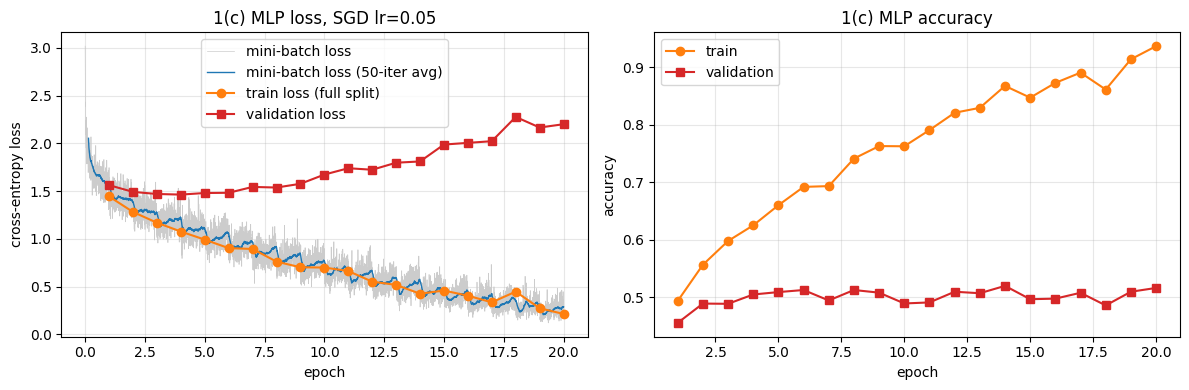

final validation accuracy: 0.5162 (epoch 20)
best validation accuracy:  0.5198 (epoch 14)
final train accuracy:      0.9369


In [9]:
iters_per_epoch = math.ceil(len(X_train) / BATCH_1C)
epochs = np.arange(1, len(hist_1c['val_acc']) + 1)
it = np.arange(1, len(hist_1c['iter_loss']) + 1) / iters_per_epoch
win = min(50, len(hist_1c['iter_loss']))
smooth = np.convolve(hist_1c['iter_loss'], np.ones(win) / win, mode='valid')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(it, hist_1c['iter_loss'], color='0.8', lw=0.5, label='mini-batch loss')
ax1.plot(it[win - 1:], smooth, color='C0', lw=1, label=f'mini-batch loss ({win}-iter avg)')
ax1.plot(epochs, hist_1c['train_loss'], 'o-', color='C1', label='train loss (full split)')
ax1.plot(epochs, hist_1c['val_loss'], 's-', color='C3', label='validation loss')
ax1.set(xlabel='epoch', ylabel='cross-entropy loss', title=f'1(c) MLP loss, SGD lr={LR_1C}')
ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(epochs, hist_1c['train_acc'], 'o-', color='C1', label='train')
ax2.plot(epochs, hist_1c['val_acc'], 's-', color='C3', label='validation')
ax2.set(xlabel='epoch', ylabel='accuracy', title='1(c) MLP accuracy')
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

best = int(np.argmax(hist_1c['val_acc']))
print(f"final validation accuracy: {hist_1c['val_acc'][-1]:.4f} (epoch {len(epochs)})")
print(f"best validation accuracy:  {hist_1c['val_acc'][best]:.4f} (epoch {best + 1})")
print(f"final train accuracy:      {hist_1c['train_acc'][-1]:.4f}")

**Interpretation.** The MLP ends with a validation accuracy of 51.6% (best 52.0%, at epoch 14), compared with 10%
for guessing. So it does learn something from raw pixels, but the plots show it stops getting better on new images
very early.

- The validation loss is lowest at epoch 4 (1.46) and rises from there, up to 2.20 at epoch 20. Meanwhile the training
  loss keeps falling, from 1.45 to 0.21, and training accuracy climbs to 93.7%. From about epoch 5 onwards the network
  is mostly memorizing the training images. That is clear overfitting.
- Validation accuracy stays at roughly 50% from epoch 4 to 20, even though the validation loss goes up a lot. The loss
  can rise without the accuracy dropping because the network becomes more and more confident. When it is wrong, it is
  now very confidently wrong, and cross-entropy punishes that heavily.
- The grey mini-batch loss is very noisy, since each step only sees 128 images. The averaged curve and the full-split
  training loss follow the same trend, so the noise averages out over many steps. The training loss goes up a little
  at epochs 15 and 18, where some steps with the fairly high learning rate of 0.05 pushed the weights somewhere worse.
  A learning rate that decays during training would smooth this out.

Why only about 50%: an MLP sees the image as a flat list of 3072 numbers. It doesn't know which pixels are next to each
other, and what it learns about a cat in the top-left corner doesn't carry over to a cat in the middle. It also has
1.7M parameters for 45k images, so memorizing is easy. The CNNs in Tasks 2 to 4 get 70 to 90% on the same data with
far fewer parameters, because a convolution reuses the same small filters at every position. To get more out of this
MLP I would stop around epoch 5 (early stopping) or add regularization, but an MLP's ceiling on CIFAR-10 is low anyway.

### (d) Gradient norms in a 10-layer MLP at initialization

I build a 10-layer MLP ($3072 \to 256 \to \dots \to 256 \to 10$: 10 `Linear` layers with 9 activations between them)
once with sigmoid and once with ReLU. Each gets the initialization that is normally paired with it: Xavier
($\mathrm{Var}(W) = 1/n_{\text{in}}$) for sigmoid and Kaiming ($\mathrm{Var}(W) = 2/n_{\text{in}}$) for ReLU, where
$n_{\text{in}}$ is the layer's number of inputs. Without any training, I do one forward and one backward pass on a
batch of 256 training images and record the size (Frobenius norm) of each layer's weight gradient
$\lVert \partial L / \partial W_\ell \rVert$. I repeat this for 5 random initializations, each on a different batch,
so the result isn't down to one lucky seed. The y-axis is logarithmic, because the sigmoid values span several orders
of magnitude.

Why the two should behave differently: going backwards through one layer multiplies the gradient by $W^\top$ and by
the activation's derivative $f'(z)$, so the gradient that reaches layer $\ell$ has passed through
$\prod_{k > \ell} W_k^\top \operatorname{diag}(f'(z_k))$.
- For sigmoid, $f'(z) = \sigma(z)(1 - \sigma(z))$ is at most 0.25 (at $z = 0$) and smaller everywhere else, so each
  layer can cut the gradient by a factor of 4 or more. After 9 such layers the earliest layers get almost nothing.
  Xavier initialization keeps the weights from adding to the problem but can't undo the 0.25.
- For ReLU, $f'(z)$ is exactly 1 for active units and 0 for inactive ones. About half the units are active, which
  would halve the signal's variance at every layer, and Kaiming's factor of 2 in the weight variance is there precisely
  to cancel that. So the gradient should stay at roughly the same size all the way down.

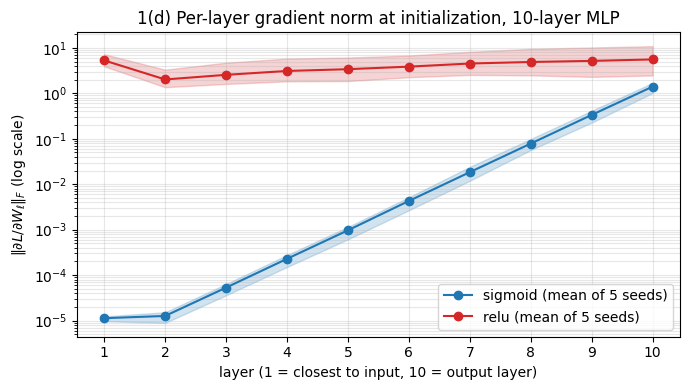

,sigmoid,relu
layer,,
1,1.13e-05,5.31e+00
2,1.26e-05,2.02e+00
3,5.31e-05,2.56e+00
4,2.29e-04,3.11e+00
5,9.70e-04,3.41e+00
6,4.29e-03,3.88e+00
7,1.84e-02,4.54e+00
8,7.85e-02,4.91e+00
9,3.36e-01,5.19e+00


sigmoid : layer-1 / layer-10 gradient norm ratio = 8.02e-06
relu    : layer-1 / layer-10 gradient norm ratio = 9.51e-01


In [10]:
def layer_grad_norms(activation, seed, depth=10, width=256, batch=256):
    """Per-layer weight-gradient norms of a freshly initialized depth-layer manual MLP on one batch."""
    set_seed(seed)
    mlp = MLP([3 * 32 * 32] + [width] * (depth - 1) + [10], activation=activation)
    xb, yb = X_train[seed * batch:(seed + 1) * batch], Y_train[seed * batch:(seed + 1) * batch]
    mlp.loss(xb, yb)
    mlp.backward()
    return [l.dW.norm().item() for l in mlp.linear_layers()]

SEEDS_1D = range(5)
norms_1d = {act: np.array([layer_grad_norms(act, s) for s in SEEDS_1D]) for act in ['sigmoid', 'relu']}
layers = np.arange(1, 11)

fig, ax = plt.subplots(figsize=(7, 4))
for act, color in [('sigmoid', 'C0'), ('relu', 'C3')]:
    n = norms_1d[act]
    ax.semilogy(layers, n.mean(axis=0), 'o-', color=color, label=f'{act} (mean of {len(SEEDS_1D)} seeds)')
    ax.fill_between(layers, n.min(axis=0), n.max(axis=0), color=color, alpha=0.2)
ax.set(xlabel='layer (1 = closest to input, 10 = output layer)', ylabel=r'$\|\partial L/\partial W_\ell\|_F$ (log scale)',
       title='1(d) Per-layer gradient norm at initialization, 10-layer MLP')
ax.set_xticks(layers); ax.legend(); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

table_1d = pd.DataFrame({act: norms_1d[act].mean(axis=0) for act in norms_1d}, index=pd.Index(layers, name='layer'))
with pd.option_context('display.float_format', '{:.2e}'.format):
    display(table_1d)
for act in norms_1d:
    m = norms_1d[act].mean(axis=0)
    print(f'{act:8s}: layer-1 / layer-10 gradient norm ratio = {m[0] / m[-1]:.2e}')

**Interpretation.** The plot shows the difference very clearly.

With **sigmoid**, the gradient norm is 1.41 at the output layer and falls steadily going back towards the input: 0.34
at layer 9, 0.079 at layer 8, and so on, down to about $1.1 \times 10^{-5}$ at layer 1. The first layer gets a gradient
about $10^5$ times smaller than the last one (the ratio is $8 \times 10^{-6}$). On the log plot the drop is almost a
straight line, about a factor of 4.3 per layer, which is very close to the factor of 4 that $\sigma'(z) \le 0.25$
predicts. Layers 1 and 2 come out about the same. I think that's because layer 1's input is the raw image, which is
much larger than the sigmoid outputs (between 0 and 1) feeding the other layers, and $\partial L/\partial W = G^\top X$
grows with the input. In practice, if I trained this network with SGD the first layers would barely move at all. That
is the vanishing gradient problem.

With **ReLU** and Kaiming initialization, every layer gets a gradient of the same order, between 2.0 and 5.6, and the
ratio between layer 1 and layer 10 is 0.95. Kaiming's factor of 2 makes up for ReLU switching off about half the units,
so the gradient keeps its size as it goes backwards, and all the layers can start learning at a similar speed. The
shaded bands (minimum to maximum over the 5 seeds) are narrow, so this isn't down to one particular initialization.

## Task 2: Optimizers

### Shared training code for the CNN experiments (Tasks 2–4)

From here on the models are ordinary `nn.Module`s trained with autograd. Rather than repeat the training loop in
every task, I write it once here.

- `SmallCNN` is the "small CNN" used in Tasks 2(c) and 3(a): three stages of two 3×3 convolutions (32, 64 and 128
  channels), each stage followed by 2×2 max-pooling, then global average pooling and a single linear layer, about
  0.29M parameters in total. Batch norm (after every convolution) and dropout (after every stage) can be switched on.
  Task 2(c) uses neither; Task 3(a) uses batch norm.
- `train_model` runs the epochs and returns a history dict. For every epoch it records the average mini-batch
  training loss, the validation loss and accuracy and, if asked, the accuracy on a set of clean training images. It can
  apply a data-augmentation function to each batch, mixup, label smoothing, and a learning-rate scheduler that is
  stepped after every batch. If the loss becomes NaN or infinite, it stops and marks the run as diverged.
- Training uses mixed precision (`torch.autocast` with float16, plus a `GradScaler`) and the channels-last memory
  layout. Both make convolutions on the T4 noticeably faster, because its tensor cores only work in float16. The
  `GradScaler` multiplies the loss by a large factor before `backward()`, so that small float16 gradients don't round
  to zero, and divides it back out before the optimizer step.
- `run_cached` saves each run's history as JSON in `./results` and loads it instead of retraining if the file exists.

In [11]:
BATCH = 128

class SmallCNN(nn.Module):
    """3 stages of two 3x3 convs (32/64/128 channels), max-pool after each stage, global average pool, linear layer.
    Optional batch norm after every conv and dropout after every stage."""
    def __init__(self, batch_norm=False, dropout=0.0, widths=(32, 64, 128)):
        super().__init__()
        layers, in_c = [], 3
        for w in widths:
            for _ in range(2):
                layers.append(nn.Conv2d(in_c, w, 3, padding=1, bias=not batch_norm))
                if batch_norm:
                    layers.append(nn.BatchNorm2d(w))
                layers.append(nn.ReLU(inplace=True))
                in_c = w
            layers.append(nn.MaxPool2d(2))
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(in_c, 10)

    def forward(self, x):
        return self.classifier(self.features(x).mean(dim=(2, 3)))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def evaluate(model, X, Y, amp=True, batch_size=1000):
    """Mean cross-entropy and accuracy of model on (X, Y), in eval mode."""
    model.eval()
    total_loss, correct = 0.0, 0
    for xb, yb in batches(X, Y, batch_size, shuffle=False):
        with torch.autocast(device.type, dtype=torch.float16, enabled=amp and device.type == 'cuda'):
            out = model(xb.contiguous(memory_format=torch.channels_last)).float()
        total_loss += F.cross_entropy(out, yb, reduction='sum').item()
        correct += (out.argmax(dim=1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


def train_model(model, optimizer, X, Y, epochs, scheduler=None, augment=None, mixup_alpha=0.0,
                label_smoothing=0.0, eval_train=None, amp=True, batch_size=BATCH, print_every=5):
    """Train for `epochs` epochs and return the per-epoch history.
    scheduler is stepped after every mini-batch; augment(x) is applied to every training batch on the GPU;
    eval_train=(X, Y) also records the accuracy on those clean (un-augmented) images after every epoch."""
    use_amp = amp and device.type == 'cuda'
    model.to(device, memory_format=torch.channels_last)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': [], 'diverged': False}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, n_seen = torch.zeros((), device=device), 0
        for xb, yb in batches(X, Y, batch_size):
            if augment is not None:
                xb = augment(xb)
            if mixup_alpha > 0:
                xb, yb_partner, lam = mixup_batch(xb, yb, mixup_alpha)  # defined in Task 3(a)
            xb = xb.contiguous(memory_format=torch.channels_last)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
                if mixup_alpha > 0:
                    loss = lam * loss + (1 - lam) * F.cross_entropy(out, yb_partner, label_smoothing=label_smoothing)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
            loss_sum += loss.detach().float() * len(xb)
            n_seen += len(xb)
        hist['train_loss'].append((loss_sum / n_seen).item())
        hist['lr'].append(optimizer.param_groups[0]['lr'])
        if eval_train is not None:
            hist['train_acc'].append(evaluate(model, *eval_train, amp=amp)[1])
        val_loss, val_acc = evaluate(model, X_val, Y_val, amp=amp)
        hist['val_loss'].append(val_loss)
        hist['val_acc'].append(val_acc)
        diverged = not math.isfinite(hist['train_loss'][-1])
        if epoch % print_every == 0 or epoch == epochs or diverged:
            train_acc = f" train acc {hist['train_acc'][-1]:.3f} |" if eval_train is not None else ''
            print(f"  epoch {epoch:3d} | train loss {hist['train_loss'][-1]:.4f} |{train_acc} "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f} | {time.time() - t0:.0f} s")
        if diverged:
            print('  the training loss is not finite: this run diverged, stopping it here')
            hist['diverged'] = True
            break
    hist['time'] = time.time() - t0
    return hist


def run_cached(name, train_fn):
    """Return the saved history of run `name` if there is one, otherwise call train_fn() and save its history."""
    path = f'{RESULTS_DIR}/{name}.json'
    if os.path.exists(path):
        with open(path) as f:
            hist = json.load(f)
        print(f'{name}: loaded saved run (final val acc {hist["val_acc"][-1]:.4f})')
        return hist
    print(f'{name}:')
    hist = train_fn()
    with open(path, 'w') as f:
        json.dump(hist, f)
    return hist

### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

Subclassing `torch.optim.Optimizer` means I only have to write `step()`. The base class keeps the parameters in
`self.param_groups` (each group is a dict holding the parameters and their settings, such as `lr`) and gives me a
per-parameter `self.state` dict, which is where the momentum buffer and Adam's running averages live. Because the
settings sit in the param groups, PyTorch's learning-rate schedulers and the `GradScaler` work with my optimizers
without any changes, which I rely on in Tasks 3 and 4.

**SGD with momentum.** I use PyTorch's form of the update:
$$v_t = \mu\, v_{t-1} + g_t, \qquad \theta_t = \theta_{t-1} - \eta\, v_t, \qquad v_1 = g_1 .$$
The velocity $v$ is a decaying sum of past gradients. In a direction where the gradient keeps the same sign, the terms
pile up and the step grows towards $1/(1-\mu) = 10$ times the plain SGD step (for $\mu = 0.9$). In a direction where the
gradient keeps flipping sign, the terms largely cancel. Some textbooks write $v_t = \mu v_{t-1} - \eta g_t$ instead;
that is the same thing while $\eta$ is constant, but behaves differently once the learning rate changes during
training, so to match `torch.optim.SGD` exactly I use PyTorch's version. With $\mu = 0$ the class is plain SGD.

**Adam.** Adam keeps two running averages for every parameter, one of the gradient and one of the squared gradient:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\, g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)\, g_t^2,$$
$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^t}, \qquad
\theta_t = \theta_{t-1} - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.$$
Dividing by $\sqrt{\hat v_t}$ gives every parameter its own step size. A parameter whose gradients are consistently
large gets its step scaled down and one with small gradients gets it scaled up, so the step ends up roughly $\eta$ in
size whatever the scale of the gradient. I use the usual $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$.

The bias correction is there because $m$ and $v$ start at zero. After the first step, $m_1 = 0.1\,g_1$ and
$v_1 = 0.001\,g_1^2$, which badly underestimate the gradient and its square. Dividing by $1 - \beta^t$ fixes this
exactly at $t = 1$ ($\hat m_1 = g_1$, $\hat v_1 = g_1^2$), and the correction fades away as $t$ grows. Without it the
first update would be $0.1\,g / \sqrt{0.001\,g^2} \approx 3.2$ times bigger than intended.

Both classes also take a `weight_decay` $\lambda$, done the same way as PyTorch's `SGD` and `Adam`: $\lambda\theta$ is
added to the gradient before anything else, which is ordinary L2 regularization. Task 3 needs it.

In [12]:
class MySGD(torch.optim.Optimizer):
    """SGD with optional momentum and L2 weight decay, using the same update rule as torch.optim.SGD."""
    def __init__(self, params, lr, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad + wd * p
                if mu != 0:
                    state = self.state[p]
                    if 'velocity' not in state:
                        state['velocity'] = g.clone()       # v_1 = g_1
                    else:
                        state['velocity'].mul_(mu).add_(g)  # v_t = mu * v_{t-1} + g_t
                    g = state['velocity']
                p.add_(g, alpha=-lr)                        # theta <- theta - lr * v_t
        return loss


class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction and optional L2 weight decay, using the same update rule as torch.optim.Adam."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (beta1, beta2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad + wd * p
                state = self.state[p]
                if not state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t, m, v = state['t'], state['m'], state['v']
                m.mul_(beta1).add_(g, alpha=1 - beta1)         # m_t = b1 m + (1 - b1) g
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)  # v_t = b2 v + (1 - b2) g^2
                m_hat = m / (1 - beta1 ** t)                   # bias correction
                v_hat = v / (1 - beta2 ** t)
                p.sub_(lr * m_hat / (v_hat.sqrt() + eps))
        return loss

To show my classes match PyTorch's, I make two identical copies of a small CNN (with batch norm, so the BN parameters
get updated as well), give one my optimizer and the other PyTorch's with the same settings, and train both on the same
20 mini-batches. Then I compare every parameter with `torch.allclose`. This runs in float64 so that the optimizer code
is the only thing that could make the two copies differ. I also print how far the parameters moved from their starting
values, to show that the difference between the copies is tiny compared with the updates themselves.

In [13]:
def compare_with_torch(make_mine, make_ref, steps=20, batch=64):
    """Train two identical float64 copies of a small CNN on the same batches, one with each optimizer, and compare."""
    set_seed()
    model_mine = SmallCNN(batch_norm=True).to(device).double()
    model_ref = copy.deepcopy(model_mine)
    start = [p.detach().clone() for p in model_mine.parameters()]
    opt_mine, opt_ref = make_mine(model_mine.parameters()), make_ref(model_ref.parameters())
    for s in range(steps):
        xb, yb = X_train[s * batch:(s + 1) * batch].double(), Y_train[s * batch:(s + 1) * batch]
        for model, opt in [(model_mine, opt_mine), (model_ref, opt_ref)]:
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    pairs = list(zip(model_mine.parameters(), model_ref.parameters()))
    return dict(max_abs_diff=max((a - b).abs().max().item() for a, b in pairs),
                max_change_from_init=max((a - s).abs().max().item() for (a, _), s in zip(pairs, start)),
                allclose=all(torch.allclose(a, b) for a, b in pairs))

COMPARISONS_2A = {
    'SGD, lr=0.1': (lambda p: MySGD(p, lr=0.1),
                    lambda p: torch.optim.SGD(p, lr=0.1)),
    'SGD + momentum 0.9, lr=0.05': (lambda p: MySGD(p, lr=0.05, momentum=0.9),
                                    lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
    'SGD + momentum + weight decay 5e-4': (lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4),
                                           lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4)),
    'Adam, lr=1e-3': (lambda p: MyAdam(p, lr=1e-3),
                      lambda p: torch.optim.Adam(p, lr=1e-3)),
    'Adam + weight decay 5e-4': (lambda p: MyAdam(p, lr=1e-3, weight_decay=5e-4),
                                 lambda p: torch.optim.Adam(p, lr=1e-3, weight_decay=5e-4)),
}
table_2a = pd.DataFrame([dict(optimizer=name, **compare_with_torch(*fns)) for name, fns in COMPARISONS_2A.items()])
with pd.option_context('display.float_format', '{:.2e}'.format):
    display(table_2a)

,optimizer,max_abs_diff,max_change_from_init,allclose
0,"SGD, lr=0.1",2.22e-16,3.07e-02,True
1,"SGD + momentum 0.9, lr=0.05",6.45e-16,8.18e-02,True
2,SGD + momentum + weight decay 5e-4,4.44e-16,8.09e-02,True
3,"Adam, lr=1e-3",4.05e-15,1.78e-02,True
4,Adam + weight decay 5e-4,2.44e-14,1.75e-02,True


**Interpretation.** All five configurations match PyTorch: `torch.allclose` is True for every parameter. After 20
steps, the largest difference between my copy of the network and PyTorch's copy is $2 \times 10^{-16}$ to
$6 \times 10^{-16}$ for SGD and $4 \times 10^{-15}$ to $2.4 \times 10^{-14}$ for Adam. Over the same 20 steps the
parameters moved by up to 0.018 to 0.082 from where they started, so the differences are about 12 orders of magnitude
smaller than the updates. They are only float64 rounding.

Adam's differences are a bit bigger than SGD's because PyTorch evaluates the same formula in a different order: it
folds the bias corrections into the step size and the denominator, instead of dividing $m$ and $v$ first as I do.
Mathematically it's identical, but the rounding happens in different places, and dividing by $\sqrt{\hat v}$ (which
can be small) makes those rounding differences slightly larger. So my momentum buffer, bias correction and weight decay
all work the same way as PyTorch's, and I can safely use my classes for the rest of the assignment.

### (b) Trajectories on an ill-conditioned quadratic

$f(x, y) = \tfrac12(x^2 + 50y^2)$ has its minimum at the origin. Its gradient is $(x, 50y)$, and its curvature is 1
along $x$ but 50 along $y$: the bowl is 50 times steeper in one direction than the other (condition number 50).
Neural-network loss surfaces have the same kind of problem, with some directions far steeper than others, so this is
a small, fully understandable version of it.

There's no data here, so "SGD" is really full-batch gradient descent: every step uses the exact gradient. All three
optimizers start at $(-10, 1)$ and take 100 steps, using my classes from (a).

For plain gradient descent the two coordinates evolve separately: $x \leftarrow (1-\eta)\,x$ and
$y \leftarrow (1-50\eta)\,y$. The $y$ update only shrinks $y$ if $|1 - 50\eta| < 1$, that is $\eta < 2/50 = 0.04$,
so the steep direction sets the speed limit for the whole problem. I use $\eta = 0.035$, just under that limit. Then
each step multiplies $y$ by $-0.75$ (it changes sign every step, a zig-zag that slowly dies down) and $x$ by $0.965$
(a slow crawl along the flat valley floor). Momentum uses the same $\eta = 0.035$ with $\mu = 0.9$, so any difference
from plain SGD comes from the momentum alone. Adam gets $\eta = 0.3$: its step size is set directly by $\eta$ rather
than by the gradient's size, so its learning rate isn't on the same scale as the other two.

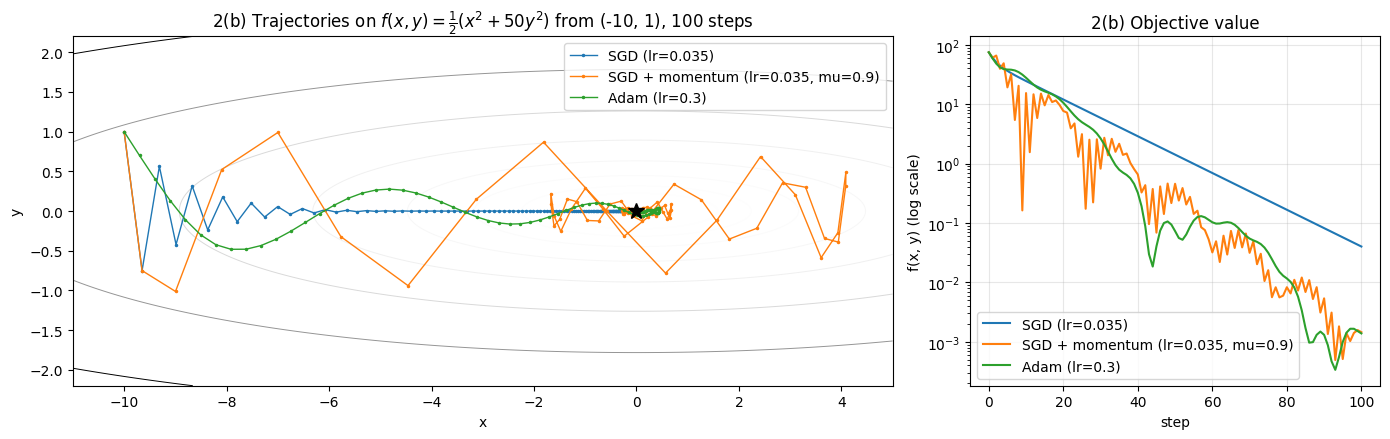

SGD (lr=0.035)                      final point (-0.2836,  0.0000)   f = 4.02e-02
SGD + momentum (lr=0.035, mu=0.9)   final point (-0.0451,  0.0042)   f = 1.45e-03
Adam (lr=0.3)                       final point (-0.0513, -0.0016)   f = 1.38e-03


In [14]:
def f_quad(w):
    return 0.5 * (w[0] ** 2 + 50 * w[1] ** 2)

def trajectory(make_opt, start=(-10.0, 1.0), steps=100):
    """Run an optimizer on f_quad from `start` and return the visited points, shape (steps + 1, 2)."""
    w = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([w])
    path = [w.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        f_quad(w).backward()
        opt.step()
        path.append(w.detach().clone())
    return torch.stack(path).numpy()

paths_2b = {
    'SGD (lr=0.035)': trajectory(lambda p: MySGD(p, lr=0.035)),
    'SGD + momentum (lr=0.035, mu=0.9)': trajectory(lambda p: MySGD(p, lr=0.035, momentum=0.9)),
    'Adam (lr=0.3)': trajectory(lambda p: MyAdam(p, lr=0.3)),
}

xs, ys = np.meshgrid(np.linspace(-11, 5, 400), np.linspace(-2.2, 2.2, 400))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 1]})
ax1.contour(xs, ys, f_quad((xs, ys)), levels=np.logspace(-2, 2.2, 15), cmap='Greys', linewidths=0.7)
for (name, path), color in zip(paths_2b.items(), ['C0', 'C1', 'C2']):
    ax1.plot(path[:, 0], path[:, 1], '.-', color=color, lw=1, ms=3, label=name)
    ax2.semilogy([f_quad(p) for p in path], color=color, label=name)
ax1.plot(0, 0, 'k*', ms=12)
ax1.set(xlabel='x', ylabel='y', title=r'2(b) Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$ from (-10, 1), 100 steps')
ax1.legend(loc='upper right')
ax2.set(xlabel='step', ylabel='f(x, y) (log scale)', title='2(b) Objective value')
ax2.grid(alpha=0.3); ax2.legend()
plt.tight_layout(); plt.show()

for name, path in paths_2b.items():
    print(f'{name:35s} final point ({path[-1, 0]: .4f}, {path[-1, 1]: .4f})   f = {f_quad(path[-1]):.2e}')

**Interpretation.** The three optimizers take very different routes to the same minimum.

- **SGD** behaves exactly as the analysis above predicts. Along $y$ it overshoots every step (factor $-0.75$), so the
  path zig-zags across the narrow valley, but that dies out within about 15 steps. After that it is stuck crawling
  along $x$ at a factor of $0.965$ per step, which is why its objective curve is a straight line on the log plot. After
  100 steps it is still at $x \approx -0.28$ ($10 \times 0.965^{100} = 0.28$), with $f \approx 4 \times 10^{-2}$. The
  steep $y$ direction forces a small learning rate, and the small learning rate makes progress along the flat $x$
  direction slow. That is the basic problem with ill-conditioning.
- **SGD with momentum** uses the same learning rate but ends up about 30 times lower ($f \approx 1.5 \times 10^{-3}$).
  Along $x$ the gradient always points the same way, so the velocity builds up and the iterate moves much faster than
  plain SGD. It even overshoots the minimum, reaching $x \approx 4$, before swinging back. The price is visible in $y$:
  the oscillation across the valley is larger and takes longer to die out than with plain SGD, because the velocity
  carries each overshoot into the next step. The objective goes down overall but not monotonically, the typical
  "heavy ball" behaviour.
- **Adam** takes a smooth, curved path. Dividing by $\sqrt{\hat v}$ rescales each coordinate separately, so the steep
  $y$ direction no longer dominates: the $y$ oscillation is damped within a few steps, and Adam then moves along $x$ at
  a roughly constant speed set by its learning rate (about 0.25 per step) rather than by the size of the gradient. It
  reaches the neighbourhood of the minimum after about 40 steps. With a fixed learning rate it can't settle exactly,
  so it keeps wobbling around the minimum, which is why its objective levels off around $10^{-3}$ instead of continuing
  to fall.

In short: plain SGD is limited by the steepest direction; momentum speeds up the consistent, flat direction at the
cost of more oscillation; and Adam's per-coordinate scaling largely removes the effect of the bad conditioning.

### (c) Learning-rate sensitivity on a small CNN

I train `SmallCNN` (no batch norm, no dropout, about 0.29M parameters) with plain SGD, SGD with momentum
($\mu = 0.9$) and Adam, each at three learning rates: $10^{-3}$, $10^{-2}$ and $10^{-1}$. That's 9 runs of 10 epochs
on the 45k training images, batch size 128, constant learning rate, no augmentation, all starting from the same
initial weights. The optimizers are my own classes from (a).

Some of these choices are deliberate:
- **No batch norm.** Batch norm makes a network much less sensitive to the learning rate, which would hide the very
  differences this experiment is supposed to show.
- **The same learning-rate grid for all three.** This shows that each optimizer prefers a different range. Momentum
  effectively multiplies the step by $1/(1-\mu) = 10$ once the velocity has built up, so it should want a learning
  rate about 10 times smaller than plain SGD. Adam's step size is roughly $\eta$ whatever the gradient's size, so it
  usually wants something near $10^{-3}$.
- **Plain float32, no mixed precision.** The `GradScaler` used with mixed precision quietly skips steps whose gradients
  overflow, which would hide a diverging run rather than show it.

For each optimizer, the "best rate" is the one with the highest validation accuracy after the last epoch.

In [15]:
EPOCHS_2C = 10
LRS_2C = [1e-3, 1e-2, 1e-1]
OPTIMIZERS_2C = {
    'SGD': lambda params, lr: MySGD(params, lr=lr),
    'SGD + momentum': lambda params, lr: MySGD(params, lr=lr, momentum=0.9),
    'Adam': lambda params, lr: MyAdam(params, lr=lr),
}
print('SmallCNN parameters (no batch norm):', count_params(SmallCNN()))

results_2c = {}
for opt_name, make_opt in OPTIMIZERS_2C.items():
    for lr in LRS_2C:
        def run():
            set_seed()
            model = SmallCNN().to(device)
            return train_model(model, make_opt(model.parameters(), lr), X_train, Y_train, EPOCHS_2C, amp=False)
        results_2c[(opt_name, lr)] = run_cached(f"2c_{opt_name.replace(' + ', '_')}_lr{lr:g}", run)

SmallCNN parameters (no batch norm): 288298
2c_SGD_lr0.001:
  epoch   5 | train loss 2.3035 | val loss 2.3031 acc 0.1044 | 39 s
  epoch  10 | train loss 2.3030 | val loss 2.3028 acc 0.1058 | 73 s
2c_SGD_lr0.01:
  epoch   5 | train loss 2.3003 | val loss 2.2996 acc 0.1286 | 34 s
  epoch  10 | train loss 1.9224 | val loss 1.8728 acc 0.2798 | 68 s
2c_SGD_lr0.1:
  epoch   5 | train loss 1.5761 | val loss 1.5408 acc 0.4298 | 34 s
  epoch  10 | train loss 1.1085 | val loss 1.1229 acc 0.6096 | 68 s
2c_SGD_momentum_lr0.001:
  epoch   5 | train loss 2.3004 | val loss 2.2998 acc 0.1204 | 34 s
  epoch  10 | train loss 1.9098 | val loss 1.8661 acc 0.2870 | 69 s
2c_SGD_momentum_lr0.01:
  epoch   5 | train loss 1.3581 | val loss 1.2888 acc 0.5230 | 34 s
  epoch  10 | train loss 0.8593 | val loss 0.8796 acc 0.6950 | 68 s
2c_SGD_momentum_lr0.1:
  epoch   5 | train loss 1.0087 | val loss 1.0572 acc 0.6190 | 34 s
  epoch  10 | train loss 0.7250 | val loss 0.8641 acc 0.7148 | 68 s
2c_Adam_lr0.001:
  epoc

validation accuracy after the last epoch:


lr,0.001,0.010,0.100
optimizer,,,
Adam,0.7684,0.1028,0.0954
SGD,0.1058,0.2798,0.6096
SGD + momentum,0.2870,0.6950,0.7148


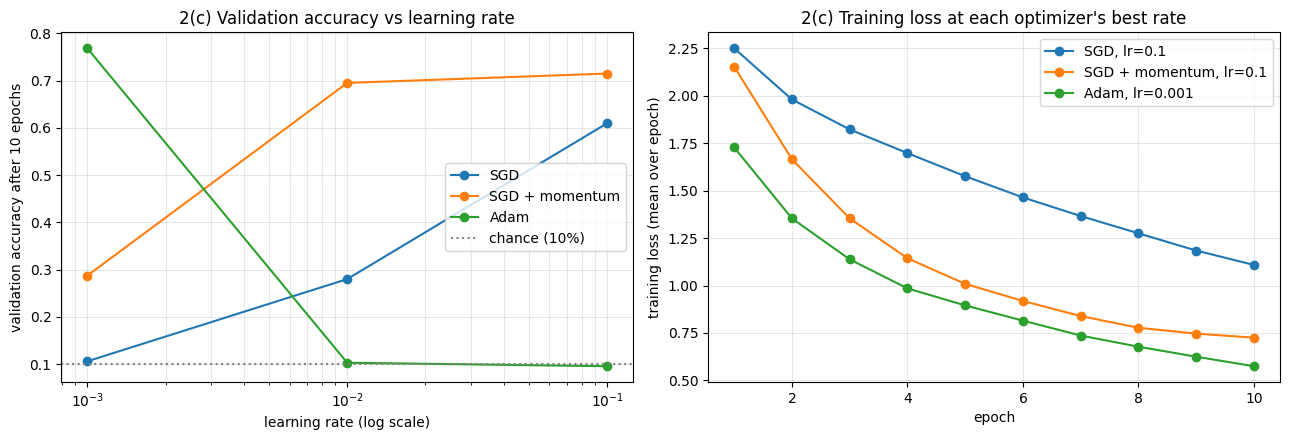

In [16]:
table_2c = pd.DataFrame([dict(optimizer=o, lr=lr, final_val_acc=h['val_acc'][-1], final_train_loss=h['train_loss'][-1],
                              diverged=h['diverged']) for (o, lr), h in results_2c.items()])
print('validation accuracy after the last epoch:')
display(table_2c.pivot(index='optimizer', columns='lr', values='final_val_acc').round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for opt_name, color in zip(OPTIMIZERS_2C, ['C0', 'C1', 'C2']):
    accs = [results_2c[(opt_name, lr)]['val_acc'][-1] for lr in LRS_2C]
    ax1.semilogx(LRS_2C, accs, 'o-', color=color, label=opt_name)
    best_lr = LRS_2C[int(np.argmax(accs))]
    h = results_2c[(opt_name, best_lr)]
    ax2.plot(range(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', color=color, label=f'{opt_name}, lr={best_lr:g}')
ax1.axhline(0.1, color='grey', ls=':', label='chance (10%)')
ax1.set(xlabel='learning rate (log scale)', ylabel=f'validation accuracy after {EPOCHS_2C} epochs',
        title='2(c) Validation accuracy vs learning rate')
ax1.legend(); ax1.grid(alpha=0.3, which='both')
ax2.set(xlabel='epoch', ylabel='training loss (mean over epoch)', title="2(c) Training loss at each optimizer's best rate")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation.** The table and the left plot show that each optimizer works in a different learning-rate range.

- **Plain SGD** does best at the largest rate I tried, 0.1 (61.0%). At 0.001 it learned nothing in 10 epochs: its loss
  is still 2.303 = ln 10 and validation accuracy is 10.6%, which is chance.
- **Adam** is the opposite. It only works at 0.001, where it gets the best result in the whole table (76.8%), and it is
  stuck at chance at both 0.01 and 0.1.
- **SGD with momentum** sits in between and does well at both 0.01 (69.5%) and 0.1 (71.5%).

**Momentum acts like a 10 times larger learning rate.** Momentum at 0.001 gives almost exactly the same result as plain
SGD at 0.01 (28.7% vs 28.0%), which is what the $1/(1-\mu) = 10$ factor predicts. It is also better than plain SGD at
the same effective step size: momentum at 0.01 (effectively 0.1) reaches 69.5%, while plain SGD at 0.1 gets 61.0%,
because averaging over steps also smooths out the noise between mini-batches.

**Sensitivity.** Momentum was the least sensitive here: 0.01 and 0.1 are only 2 points apart. Plain SGD changes a lot
with the learning rate and seems to want 0.1 or more, so its true best might be above my grid. Adam was the most
sensitive: going from 0.001 to 0.01 takes it from the best result to chance. Its loss stays at exactly ln 10, which
means the network gives the same output for every image. It isn't a NaN divergence, since the loss stays finite; the
network has collapsed. My guess is that Adam's first steps, which have size about $\eta$ for *every* weight however
small its gradient, moved the weights so far that most ReLUs became permanently inactive ("dead"), so no gradient
flows through them any more.

**Slow start without batch norm.** At small learning rates SGD sits at a loss of 2.30 for several epochs before it
starts to move: at 0.01 it is still at 2.300 after 5 epochs and only reaches 1.92 by epoch 10. PyTorch's default
convolution initialization has about 6 times less variance than Kaiming's for ReLU, so the signal shrinks a lot
through the 6 conv layers, the logits start out almost zero, and the first gradients are tiny. With a small learning
rate it takes a long time to get out of that flat starting region. This is one reason batch norm helps so much.

**Training loss at the best rates** (right plot): Adam's loss is the lowest from the first epoch on (0.57 after 10
epochs), momentum comes next (0.72), and plain SGD is far behind and still falling (1.11), so it would need many more
epochs. With only 10 epochs Adam at 0.001 is the clear winner, but it is also the easiest to break with the wrong
learning rate. With only three learning rates per optimizer the grid is coarse, so "best rate" really means "best of
these three".

## Task 3: Regularization and residual connections

### (a) Regularization with only 5k training images

With only 5,000 training images (the first 5k of my shuffled 45k training split, about 500 per class), a CNN can
learn the training set almost perfectly while doing much worse on new images, so the gap between training and
validation accuracy is large. This part compares ways of closing that gap.

Every run uses the same `SmallCNN` with batch norm, trained for 60 epochs with my SGD (momentum 0.9, learning rate
0.05 decayed to zero with a cosine schedule), batch size 128 and the same seed. Only the regularizer changes:

| Run | What is added |
|---|---|
| baseline | nothing |
| weight decay | L2 penalty with $\lambda = 5 \times 10^{-4}$ |
| dropout | dropout with $p = 0.25$ after each of the three stages |
| flip+crop | random horizontal flip, then a random 32×32 crop of the image padded by 4 pixels |
| cutout | a random 16×16 square of each image set to zero |
| mixup | pairs of images, and their labels, blended together ($\alpha = 1$) |
| all combined | all five at once |

How each one works:
- **Weight decay** adds $\frac{\lambda}{2}\lVert\theta\rVert^2$ to the loss, which means adding $\lambda\theta$ to every
  gradient. It keeps pulling the weights towards zero, so they can't grow large to fit noise in the training set.
  (With batch norm there's a side effect: BN undoes the scale of the weights in front of it, so for those layers smaller
  weights mostly mean a larger effective learning rate.)
- **Dropout** sets each activation to zero with probability $p$ during training and scales the survivors by $1/(1-p)$,
  so the expected value doesn't change. The network can't rely on any single feature being present, which works a bit
  like training many thinned-out networks and averaging them. In `model.eval()` dropout is switched off.
- **Flip and crop** make new but realistic training images: a mirrored car is still a car, and shifting it a few pixels
  doesn't change what it is. The padding is zero, which after normalization is the average colour.
- **Cutout** (DeVries & Taylor, 2017) blanks out a random square, so the network has to recognize the object from what
  is left instead of relying on one telltale patch. The square's centre can be anywhere in the image, so sometimes part
  of it falls outside, as in the paper.
- **Mixup** (Zhang et al., 2018) trains on blends of two images, $\tilde x = \lambda x_i + (1-\lambda)x_j$, with the loss
  $\lambda\,\mathrm{CE}(\tilde x, y_i) + (1-\lambda)\,\mathrm{CE}(\tilde x, y_j)$. Here $\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ is drawn
  once per batch and $x_j$ is a random other image from the same batch; with $\alpha = 1$, $\lambda$ is uniform on
  $[0, 1]$. This punishes overconfident predictions and encourages the network to behave smoothly between training examples.

I implement flip+crop, cutout and mixup myself below. Each works on the whole batch at once on the GPU, with no Python
loop over images.

**How I measure the gap.** With augmentation or mixup, the loss and accuracy seen during training are on distorted
images, which would make the gap look smaller than it really is. So after every epoch I measure the accuracy on the
clean, un-augmented 5k training images with the model in eval mode (dropout off, batch norm using its running
statistics), exactly as for the validation images. The gap is this clean training accuracy minus the validation
accuracy, at the end of training.

In [17]:
def random_crop_flip(x, pad=4):
    """Random crop from the image zero-padded by `pad` pixels, plus a random horizontal flip, for a whole batch."""
    n, c, h, w = x.shape
    padded = F.pad(x, (pad, pad, pad, pad))
    dy = torch.randint(0, 2 * pad + 1, (n, 1, 1), device=x.device)  # crop offsets
    dx = torch.randint(0, 2 * pad + 1, (n, 1, 1), device=x.device)
    flip = torch.rand(n, 1, 1, device=x.device) < 0.5
    cols = torch.arange(w, device=x.device).view(1, 1, w)
    cols = torch.where(flip, w - 1 - cols, cols)                     # a flipped image reads its columns right to left
    rows = dy + torch.arange(h, device=x.device).view(1, h, 1)       # (n, h, 1)
    cols = dx + cols                                                 # (n, 1, w)
    b = torch.arange(n, device=x.device).view(n, 1, 1, 1)
    ch = torch.arange(c, device=x.device).view(1, c, 1, 1)
    return padded[b, ch, rows.unsqueeze(1), cols.unsqueeze(1)]


def cutout(x, size=16):
    """Set a random size x size square of every image to zero (the mean colour); the square may overlap the border."""
    n, _, h, w = x.shape
    cy = torch.randint(0, h, (n, 1, 1), device=x.device)
    cx = torch.randint(0, w, (n, 1, 1), device=x.device)
    ys = torch.arange(h, device=x.device).view(1, h, 1)
    xs = torch.arange(w, device=x.device).view(1, 1, w)
    inside = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~inside).unsqueeze(1)


def mixup_batch(x, y, alpha):
    """Blend every image with a random partner from the same batch: x <- lam * x + (1 - lam) * x[perm].
    Returns the mixed images, the partners' labels and lam; the loss is lam * CE(y) + (1 - lam) * CE(y_partner)."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y[perm], lam

A quick visual check that the augmentations do what they should, on the first 8 training images:

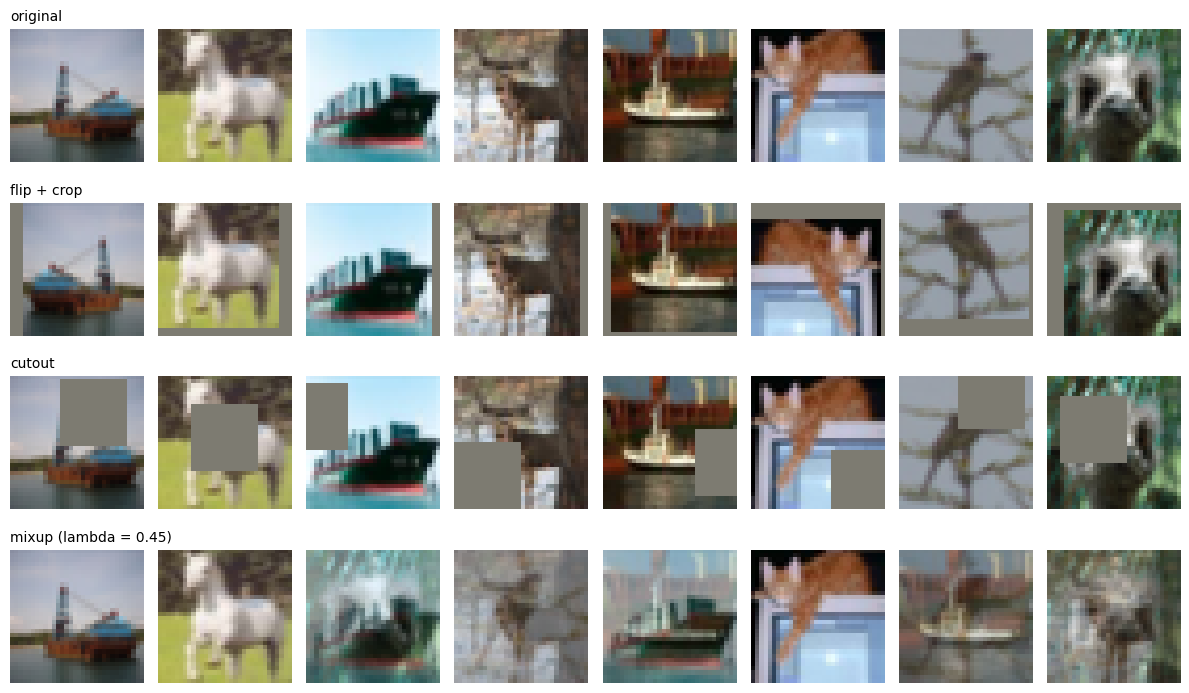

In [18]:
set_seed()
show = X_train[:8]
views = {'original': show, 'flip + crop': random_crop_flip(show), 'cutout': cutout(show)}
mixed, _, lam = mixup_batch(show, Y_train[:8], 1.0)
views[f'mixup (lambda = {lam:.2f})'] = mixed

fig, axes = plt.subplots(len(views), 8, figsize=(12, 1.8 * len(views)))
for r, (name, imgs) in enumerate(views.items()):
    imgs = (imgs.cpu() * STD.view(1, 3, 1, 1) + MEAN.view(1, 3, 1, 1)).clamp(0, 1)  # undo the normalization
    for k in range(8):
        axes[r, k].imshow(imgs[k].permute(1, 2, 0))
        axes[r, k].axis('off')
    axes[r, 0].set_title(name, loc='left', fontsize=10)
plt.tight_layout(); plt.show()

In [19]:
EPOCHS_3A, LR_3A = 60, 0.05
WD_3A, DROPOUT_3A, CUTOUT_3A, MIXUP_ALPHA_3A = 5e-4, 0.25, 16, 1.0
X_small, Y_small = X_train[:5000], Y_train[:5000]  # the split is already shuffled, so this is a random 5k subset
print('class counts in the 5k subset:', torch.bincount(Y_small.cpu()).tolist())

CONFIGS_3A = {
    'baseline': dict(),
    'weight decay': dict(weight_decay=WD_3A),
    'dropout': dict(dropout=DROPOUT_3A),
    'flip+crop': dict(augment=random_crop_flip),
    'cutout': dict(augment=lambda x: cutout(x, CUTOUT_3A)),
    'mixup': dict(mixup_alpha=MIXUP_ALPHA_3A),
    'all combined': dict(weight_decay=WD_3A, dropout=DROPOUT_3A, mixup_alpha=MIXUP_ALPHA_3A,
                         augment=lambda x: cutout(random_crop_flip(x), CUTOUT_3A)),
}

def run_3a(cfg):
    set_seed()
    model = SmallCNN(batch_norm=True, dropout=cfg.get('dropout', 0.0)).to(device)
    opt = MySGD(model.parameters(), lr=LR_3A, momentum=0.9, weight_decay=cfg.get('weight_decay', 0.0))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_3A * math.ceil(len(X_small) / BATCH))
    return train_model(model, opt, X_small, Y_small, EPOCHS_3A, scheduler=sched, augment=cfg.get('augment'),
                       mixup_alpha=cfg.get('mixup_alpha', 0.0), eval_train=(X_small, Y_small), print_every=20)

results_3a = {name: run_cached(f"3a_{name.replace(' ', '_').replace('+', '_')}", lambda: run_3a(cfg))
              for name, cfg in CONFIGS_3A.items()}

class counts in the 5k subset: [475, 477, 474, 523, 500, 500, 494, 530, 497, 530]
3a_baseline:
  epoch  20 | train loss 0.3220 | train acc 0.755 | val loss 1.7473 acc 0.5524 | 10 s
  epoch  40 | train loss 0.0113 | train acc 1.000 | val loss 1.3451 acc 0.6916 | 17 s
  epoch  60 | train loss 0.0061 | train acc 1.000 | val loss 1.3718 acc 0.6952 | 24 s
3a_weight_decay:
  epoch  20 | train loss 0.2823 | train acc 0.760 | val loss 1.4928 acc 0.5580 | 8 s
  epoch  40 | train loss 0.0095 | train acc 1.000 | val loss 1.2010 acc 0.7010 | 15 s
  epoch  60 | train loss 0.0073 | train acc 1.000 | val loss 1.2104 acc 0.6984 | 23 s
3a_dropout:
  epoch  20 | train loss 0.6550 | train acc 0.814 | val loss 1.0182 acc 0.6564 | 7 s
  epoch  40 | train loss 0.2310 | train acc 0.977 | val loss 0.9801 acc 0.7056 | 15 s
  epoch  60 | train loss 0.1325 | train acc 0.999 | val loss 0.9656 acc 0.7242 | 22 s
3a_flip_crop:
  epoch  20 | train loss 0.7531 | train acc 0.721 | val loss 1.1042 acc 0.6382 | 7 s
  epo

accuracies after the last epoch (train = clean 5k training images, eval mode):


,train_acc,val_acc,gap,best_val_acc
regularizer,,,,
baseline,1.0000,0.6952,0.3048,0.7022
weight decay,1.0000,0.6984,0.3016,0.7050
dropout,0.9992,0.7242,0.2750,0.7292
flip+crop,0.9596,0.7520,0.2076,0.7562
cutout,0.9992,0.7234,0.2758,0.7282
mixup,0.9992,0.7218,0.2774,0.7242
all combined,0.7406,0.6822,0.0584,0.6940


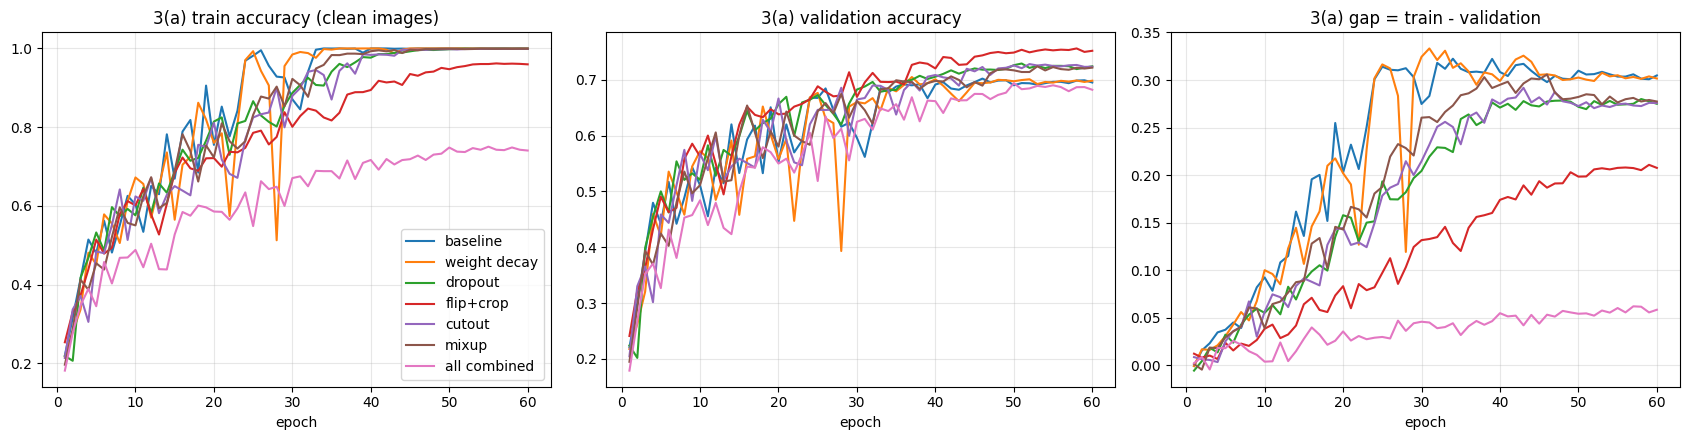

In [20]:
table_3a = pd.DataFrame([dict(regularizer=name, train_acc=h['train_acc'][-1], val_acc=h['val_acc'][-1],
                              gap=h['train_acc'][-1] - h['val_acc'][-1], best_val_acc=max(h['val_acc']))
                         for name, h in results_3a.items()]).set_index('regularizer')
print('accuracies after the last epoch (train = clean 5k training images, eval mode):')
display(table_3a.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for (name, h), color in zip(results_3a.items(), [f'C{i}' for i in range(len(results_3a))]):
    ep = np.arange(1, len(h['val_acc']) + 1)
    axes[0].plot(ep, h['train_acc'], color=color, label=name)
    axes[1].plot(ep, h['val_acc'], color=color, label=name)
    axes[2].plot(ep, np.array(h['train_acc']) - np.array(h['val_acc']), color=color, label=name)
for ax, title in zip(axes, ['train accuracy (clean images)', 'validation accuracy', 'gap = train - validation']):
    ax.set(xlabel='epoch', title=f'3(a) {title}')
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()

**Interpretation.** The baseline shows the problem clearly. It reaches 100% accuracy on the 5k training images by
around epoch 33, but only 69.5% on validation, a gap of 30.5 points. It has simply memorized the training set.

Looking at the regularizers one at a time:
- **Weight decay** made almost no difference (69.8%, gap 30.2). With batch norm after every convolution, shrinking the
  conv weights doesn't really limit what the network can do, because BN rescales them anyway; it mostly changes the
  effective learning rate. Also, 60 epochs on 5k images is only 2,400 steps, which isn't long for a penalty of
  $5 \times 10^{-4}$ to have much effect.
- **Dropout, cutout and mixup** gave almost the same gain: 72.4%, 72.3% and 72.2% on validation, about 3 points above the
  baseline, with gaps of about 27.5 points. But all three still end at 99.9% training accuracy. They slow the
  memorization down and make the network somewhat more robust, but they don't stop it. (For mixup, the training loss
  printed during training stays around 0.95 because it is measured on mixed images with mixed labels. That's why I
  measure training accuracy on the clean images, where mixup is at 99.9% like the others.)
- **Flip+crop** was the best single method by a clear margin: 75.2% on validation (+5.7 points). It was also the only
  single method that kept training accuracy below 100% (96.0%), so it had the smallest gap of the single methods,
  20.8 points. Flipping doubles the data and the crop adds 81 possible shifts, and unlike cutout and mixup these are
  realistic images, the same kind of variation the validation images actually have.
- **All combined** has by far the smallest gap, only 5.8 points, but also the *lowest* validation accuracy of all, 68.2%,
  which is below the baseline. Its training accuracy only reaches 74%. With all five at once, this small network can't
  even fit the training data in 60 epochs, so it is underfitting. The gap went down because the training accuracy
  dropped, not because the validation accuracy went up.

So a small gap is not the goal on its own; what matters is validation accuracy. Stacking every regularizer at full
strength was too much for this network and training length. Flip+crop with one milder method on top, or the full
combination trained for longer, would probably do better.

The baseline and weight-decay runs also have some sharp drops in validation accuracy between epochs 20 and 30 (once
down to 0.39). That's while the learning rate is still fairly high. My guess is that with only 5k images the batch
norm statistics jump around a lot there. The regularized runs are smoother.

Each configuration was run once, with one seed. With 5,000 validation images the standard error of an accuracy around
70% is about 0.65 points, so differences of 1 point or less (baseline vs weight decay, or dropout vs cutout vs mixup)
are within noise. The 3 to 6 point differences are well above that.

### (b) Plain vs residual networks of depth 8, 20 and 56

These are the CIFAR-10 networks from He et al. (2016), Section 4.2. A network of depth $6n + 2$ is made of:
- one 3×3 convolution with 16 channels (1 layer);
- three stages of $n$ blocks, with 16, 32 and 64 channels. Each block is two 3×3 convolutions, each followed by batch
  norm, with a ReLU in between ($2n$ layers per stage, $6n$ in all). The first block of stages 2 and 3 has stride 2,
  which halves the feature map (32×32 → 16×16 → 8×8) while the number of channels doubles;
- global average pooling and a 10-way linear layer (1 layer).

$n = 1, 3, 9$ gives depths 8, 20 and 56. Every convolution uses Kaiming (He) normal initialization, and every batch
norm layer starts with scale 1 and shift 0.

The two families differ **only in the shortcut**. A residual block outputs $\mathrm{ReLU}(F(x) + x)$, where $F$ is
the two conv–BN layers; a plain block outputs $\mathrm{ReLU}(F(x))$. Where a block changes the shape of the feature
map, $x$ can't be added as it is, so I use the paper's "option A": take every second pixel of $x$ to match the stride-2
convolution, and fill the extra channels with zeros. This shortcut has no parameters, so each plain network has
exactly the same layers and parameter count as its residual twin, and the addition is the only difference. The table
below confirms the counts.

All six networks are trained the same way: the full 45k training images, flip+crop augmentation, my SGD with momentum
0.9 and weight decay $10^{-4}$ (as in the paper), learning rate 0.1 with cosine decay to zero, batch size 128, and 30
epochs. The paper trains for about 180 epochs, which I can't afford six times over on a T4, but the effect it describes
shows up early in training.

**What to expect, and why.** In principle a deeper plain network should do at least as well as a shallower one: the
extra layers could just learn the identity and copy the shallower network. He et al. found the opposite: deeper plain
networks reach a *higher training error*, which they called the degradation problem. Because it shows up in the
training loss, it is an optimization problem, not overfitting. With batch norm the signals don't simply vanish, but a
long stack of nonlinear layers is still hard for SGD to optimize, and in particular hard to make behave like the
identity. A residual block only has to learn the *change* $F(x)$ to its input. If a block isn't useful, pushing $F$
towards zero is easy, and the block then passes $x$ through unchanged. The shortcut also gives the gradient a direct
path back to the early layers, since $\partial(F(x) + x)/\partial x = \partial F/\partial x + I$.

In [21]:
class BasicBlock(nn.Module):
    """conv3x3-BN-ReLU-conv3x3-BN, then add the shortcut (residual networks only), then ReLU."""
    def __init__(self, in_c, out_c, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.residual, self.stride, self.extra_channels = residual, stride, out_c - in_c

    def shortcut(self, x):
        # option A of He et al.: identity, or subsample and zero-pad the new channels when the shape changes (no parameters)
        if self.stride != 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra_channels > 0:
            x = F.pad(x, (0, 0, 0, 0, self.extra_channels // 2, self.extra_channels - self.extra_channels // 2))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class CifarResNet(nn.Module):
    """Depth 6n + 2 CIFAR network of He et al. (2016); residual=False gives the matching plain network."""
    def __init__(self, depth, residual=True, widths=(16, 32, 64)):
        super().__init__()
        assert (depth - 2) % 6 == 0, 'depth must be 6n + 2'
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        blocks, in_c = [], widths[0]
        for stage, w in enumerate(widths):
            for b in range(n):
                blocks.append(BasicBlock(in_c, w, stride=2 if stage > 0 and b == 0 else 1, residual=residual))
                in_c = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(in_c, 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.fc(self.blocks(self.stem(x)).mean(dim=(2, 3)))


DEPTHS_3B = [8, 20, 56]
print('number of parameters:')
display(pd.DataFrame({'plain': [count_params(CifarResNet(d, residual=False)) for d in DEPTHS_3B],
                      'residual': [count_params(CifarResNet(d, residual=True)) for d in DEPTHS_3B]},
                     index=pd.Index(DEPTHS_3B, name='depth')))

number of parameters:


,plain,residual
depth,,
8,75290,75290
20,269722,269722
56,853018,853018


In [22]:
EPOCHS_3B, LR_3B, WD_3B = 30, 0.1, 1e-4

results_3b = {}
for residual in [False, True]:
    for depth in DEPTHS_3B:
        name = f"{'residual' if residual else 'plain'}-{depth}"
        def run():
            set_seed()
            model = CifarResNet(depth, residual=residual).to(device)
            opt = MySGD(model.parameters(), lr=LR_3B, momentum=0.9, weight_decay=WD_3B)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_3B * math.ceil(len(X_train) / BATCH))
            return train_model(model, opt, X_train, Y_train, EPOCHS_3B, scheduler=sched, augment=random_crop_flip,
                               print_every=10)
        results_3b[name] = run_cached(f'3b_{name}', run)

3b_plain-8:
  epoch  10 | train loss 0.6430 | val loss 0.8557 acc 0.7278 | 23 s
  epoch  20 | train loss 0.4664 | val loss 0.5250 acc 0.8208 | 45 s
  epoch  30 | train loss 0.3910 | val loss 0.4411 acc 0.8484 | 67 s
3b_plain-20:
  epoch  10 | train loss 0.5838 | val loss 0.5937 acc 0.7984 | 49 s
  epoch  20 | train loss 0.3539 | val loss 0.4452 acc 0.8534 | 98 s
  epoch  30 | train loss 0.2320 | val loss 0.3798 acc 0.8796 | 147 s
3b_plain-56:


/tmp/ipykernel_40242/1201180213.py:72: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


  epoch  10 | train loss 1.6592 | val loss 1.6382 acc 0.3888 | 131 s
  epoch  20 | train loss 1.2862 | val loss 1.3043 acc 0.5354 | 260 s
  epoch  30 | train loss 1.0391 | val loss 1.0329 acc 0.6316 | 389 s
3b_residual-8:
  epoch  10 | train loss 0.6558 | val loss 0.7749 acc 0.7338 | 24 s
  epoch  20 | train loss 0.4829 | val loss 0.5234 acc 0.8184 | 49 s
  epoch  30 | train loss 0.3986 | val loss 0.4577 acc 0.8436 | 73 s
3b_residual-20:
  epoch  10 | train loss 0.4890 | val loss 0.6323 acc 0.7904 | 53 s
  epoch  20 | train loss 0.2767 | val loss 0.3930 acc 0.8726 | 105 s
  epoch  30 | train loss 0.1715 | val loss 0.3209 acc 0.8946 | 158 s
3b_residual-56:
  epoch  10 | train loss 0.6088 | val loss 0.6896 acc 0.7628 | 136 s
  epoch  20 | train loss 0.3204 | val loss 0.4321 acc 0.8558 | 272 s
  epoch  30 | train loss 0.1799 | val loss 0.3926 acc 0.8802 | 407 s


,final_train_loss,final_val_acc,minutes
network,,,
plain-8,0.3910,0.8484,1.1181
plain-20,0.2320,0.8796,2.4479
plain-56,1.0391,0.6316,6.4879
residual-8,0.3986,0.8436,1.2184
residual-20,0.1715,0.8946,2.6286
residual-56,0.1799,0.8802,6.7892


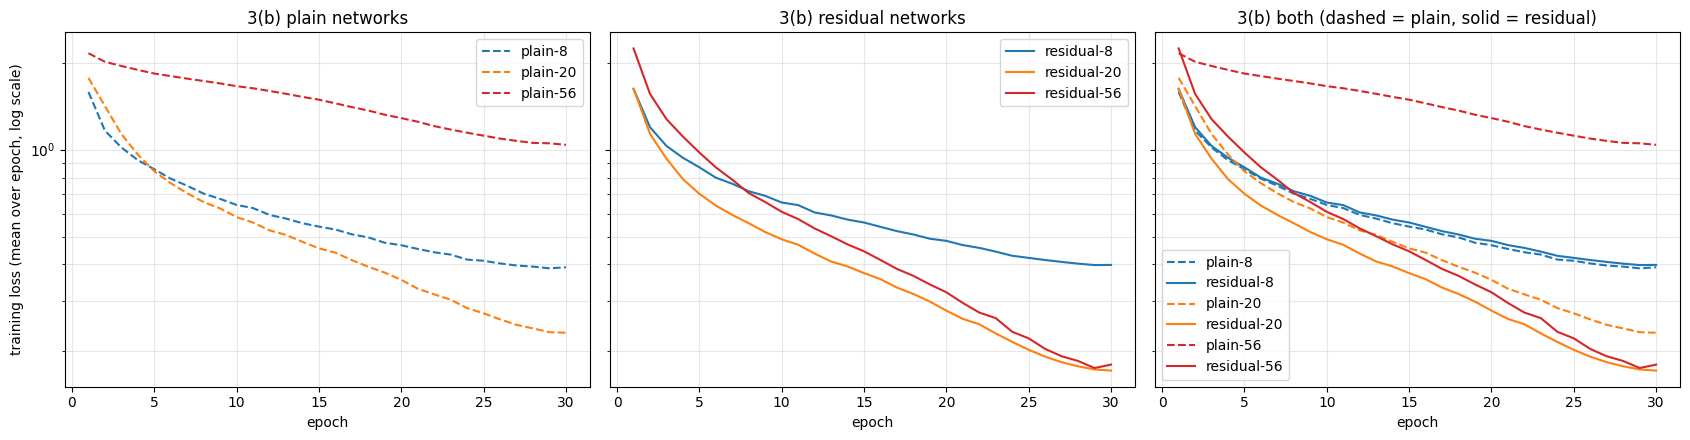

In [23]:
table_3b = pd.DataFrame([dict(network=name, final_train_loss=h['train_loss'][-1], final_val_acc=h['val_acc'][-1],
                              minutes=h['time'] / 60) for name, h in results_3b.items()]).set_index('network')
display(table_3b.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for depth, color in zip(DEPTHS_3B, ['C0', 'C1', 'C3']):
    for kind, ax, ls in [('plain', axes[0], '--'), ('residual', axes[1], '-')]:
        h = results_3b[f'{kind}-{depth}']
        ep = range(1, len(h['train_loss']) + 1)
        ax.plot(ep, h['train_loss'], ls=ls, color=color, label=f'{kind}-{depth}')
        axes[2].plot(ep, h['train_loss'], ls=ls, color=color, label=f'{kind}-{depth}')
for ax, title in zip(axes, ['plain networks', 'residual networks', 'both (dashed = plain, solid = residual)']):
    ax.set(xlabel='epoch', title=f'3(b) {title}', yscale='log')
    ax.grid(alpha=0.3, which='both'); ax.legend()
axes[0].set_ylabel('training loss (mean over epoch, log scale)')
plt.tight_layout(); plt.show()

**Interpretation.** This reproduces the degradation problem from He et al. quite clearly.

**Plain networks (left).** Going from 8 to 20 layers helps: final training loss 0.391 → 0.232, validation 84.8% →
88.0%. But going to 56 layers makes things much *worse*. Plain-56 ends with a training loss of 1.039 and only 63.2%
validation accuracy. Its training loss is higher than plain-8's at every epoch; after 30 epochs it is about where
plain-8 was after 3. Because this is the *training* loss, it isn't overfitting. The deeper plain network is just much
harder to optimize, even though it has 11 times more parameters than plain-8 and could in principle copy it.

**Residual networks (middle).** With shortcuts, extra depth doesn't hurt. Residual-20 (loss 0.172, 89.5%) is better
than residual-8 (0.399, 84.4%), and residual-56 ends at practically the same training loss as residual-20 (0.180), with
88.0% on validation. Residual-56 starts more slowly: for the first 8 or so epochs its loss is above residual-8's. After
that it overtakes residual-8 and nearly catches residual-20 by the end.

**Same depth, with and without the shortcut (right).** At depth 8 the shortcut makes no difference (0.391 vs 0.399),
since a shallow network is easy to optimize either way. At depth 20 the residual network is a little better (0.172 vs
0.232), and at depth 56 the difference is huge (0.180 vs 1.039, and 88.0% vs 63.2% on validation). In each pair the
layers and parameters are exactly the same; the only change is the $+x$ in each block, and that alone decides whether
the 56-layer network trains properly. So the benefit of residual connections grows with depth.

One thing that didn't match the paper: residual-56 didn't beat residual-20 here. In the paper ResNet-56 ends up better
than ResNet-20, but that's after about 180 epochs. With 30 epochs the deeper network hasn't had time to pull ahead
(its loss was still falling at the end), and it costs 2.6 times as much to train (6.8 vs 2.6 minutes).

The `UserWarning` in the plain-56 output comes from mixed precision. On the very first step plain-56's float16 gradients
overflowed, so the `GradScaler` skipped that step and lowered its scale factor, and the learning-rate scheduler then
warned that it had been stepped before the optimizer. It affects one step out of 10,560, so it doesn't change the
result. (The filter in the setup cell was meant to hide this warning, but its pattern didn't match the message.) It's
also a small sign of the same problem: at initialization the signals in the deep plain network are badly scaled.

## Task 4: Best CNN with at most 500k parameters and 20 epochs (optional)

**Architecture.** I reuse the residual network from 3(b) but make it shallower and wider: depth 14 ($n = 2$ blocks
per stage) with 24, 48 and 96 channels instead of 16, 32 and 64. That comes to 386,626 parameters, under the 500k limit
(the cell below prints and checks it). For the same number of parameters, fewer but wider layers run faster on a GPU
and usually reach good accuracy sooner, which matters when only 20 epochs are allowed. I kept the channel counts at
multiples of 8 because the T4's tensor cores work best with those.

**Training recipe.** I picked this recipe from standard practice for short CIFAR-10 training rather than from a large
search. The only comparisons I made are the ablation runs below, all judged on the validation split; the test set
plays no part in any choice.
- SGD with Nesterov momentum 0.9, weight decay $5 \times 10^{-4}$, batch size 128.
- A one-cycle learning-rate schedule: the learning rate climbs from 0.004 to 0.1 over the first quarter of training,
  then anneals smoothly to almost zero (the scheduler moves the momentum between 0.95 and 0.85 in the opposite
  direction). The warm-up lets the network use a high learning rate without blowing up early on, and annealing to
  zero at the end gives a jump in accuracy that a constant learning rate can't.
- Augmentation: random flip, random crop with 4 pixels of padding, and cutout with an 8×8 square. I used a smaller
  square than in Task 3 because I expected heavy augmentation to slow learning down too much in only 20 epochs; I did
  not test the 16×16 size here.
- Label smoothing 0.1: the target gives 0.9 to the true class and spreads the remaining 0.1 evenly over all ten
  classes, which stops the network from pushing its logits to extremes to become 100% confident.

**Ablation.** To see which choices actually matter, I retrain with exactly one of them changed and everything else the same:
1. **no shortcut**: the plain version of the same network (same parameters, as in 3(b)),
2. **no augmentation**: no flip, crop or cutout,
3. **no weight decay**,
4. **Adam instead of SGD**: my Adam class from Task 2, with the same one-cycle schedule and a peak learning rate of 0.002.

Each run is 20 epochs on the 45k training images and is compared on validation accuracy. The final model is the run
with the best validation accuracy, and only that model is evaluated on the test set, once.

In [24]:
EPOCHS_4, DEPTH_4, WIDTHS_4 = 20, 14, (24, 48, 96)
n_params_4 = count_params(CifarResNet(DEPTH_4, residual=True, widths=WIDTHS_4))
print(f'parameters: {n_params_4:,} (limit 500,000)')
assert n_params_4 <= 500_000

BASE_4 = dict(residual=True, augment=True, weight_decay=5e-4, optimizer='sgd')
ABLATIONS_4 = {
    'final design': {},
    'no shortcut': dict(residual=False),
    'no augmentation': dict(augment=False),
    'no weight decay': dict(weight_decay=0.0),
    'Adam instead of SGD': dict(optimizer='adam'),
}

def run_4(name, changes):
    """Train the Task 4 network with BASE_4 modified by `changes`; the final weights are saved for the test step."""
    cfg = {**BASE_4, **changes}
    set_seed()
    model = CifarResNet(DEPTH_4, residual=cfg['residual'], widths=WIDTHS_4).to(device)
    total_steps = EPOCHS_4 * math.ceil(len(X_train) / BATCH)
    if cfg['optimizer'] == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=cfg['weight_decay'])
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, total_steps=total_steps, pct_start=0.25)
    else:
        opt = MyAdam(model.parameters(), lr=2e-3, weight_decay=cfg['weight_decay'])
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=total_steps, pct_start=0.25)
    augment = (lambda x: cutout(random_crop_flip(x), 8)) if cfg['augment'] else None
    hist = train_model(model, opt, X_train, Y_train, EPOCHS_4, scheduler=sched, augment=augment, label_smoothing=0.1)
    torch.save(model.state_dict(), f"{RESULTS_DIR}/4_{name.replace(' ', '_')}.pt")
    return hist

parameters: 386,626 (limit 500,000)


In [25]:
results_4 = {name: run_cached(f"4_{name.replace(' ', '_')}", lambda: run_4(name, changes))
             for name, changes in ABLATIONS_4.items()}

4_final_design:
  epoch   5 | train loss 1.1441 | val loss 0.8821 acc 0.6998 | 23 s
  epoch  10 | train loss 0.9638 | val loss 0.7599 acc 0.7484 | 45 s
  epoch  15 | train loss 0.8602 | val loss 0.5113 acc 0.8464 | 67 s
  epoch  20 | train loss 0.7283 | val loss 0.3471 acc 0.9028 | 89 s
4_no_shortcut:
  epoch   5 | train loss 1.1424 | val loss 1.1019 acc 0.6394 | 20 s
  epoch  10 | train loss 0.9697 | val loss 0.7504 acc 0.7494 | 40 s
  epoch  15 | train loss 0.8688 | val loss 0.5626 acc 0.8320 | 60 s
  epoch  20 | train loss 0.7295 | val loss 0.3542 acc 0.9012 | 81 s
4_no_augmentation:
  epoch   5 | train loss 1.0130 | val loss 0.9050 acc 0.7036 | 21 s
  epoch  10 | train loss 0.8077 | val loss 0.6946 acc 0.7802 | 42 s
  epoch  15 | train loss 0.6461 | val loss 0.5505 acc 0.8382 | 63 s
  epoch  20 | train loss 0.5293 | val loss 0.4797 acc 0.8682 | 84 s
4_no_weight_decay:
  epoch   5 | train loss 1.1476 | val loss 0.8583 acc 0.7156 | 22 s
  epoch  10 | train loss 0.9359 | val loss 0.52

,final_val_acc,best_val_acc,final_train_loss,minutes,val_acc_change
run,,,,,
final design,0.9028,0.9028,0.7283,1.4902,0.0000
no shortcut,0.9012,0.9012,0.7295,1.3451,-0.0016
no augmentation,0.8682,0.8684,0.5293,1.4046,-0.0346
no weight decay,0.8834,0.8874,0.7646,1.4550,-0.0194
Adam instead of SGD,0.8862,0.8870,0.7511,2.0234,-0.0166


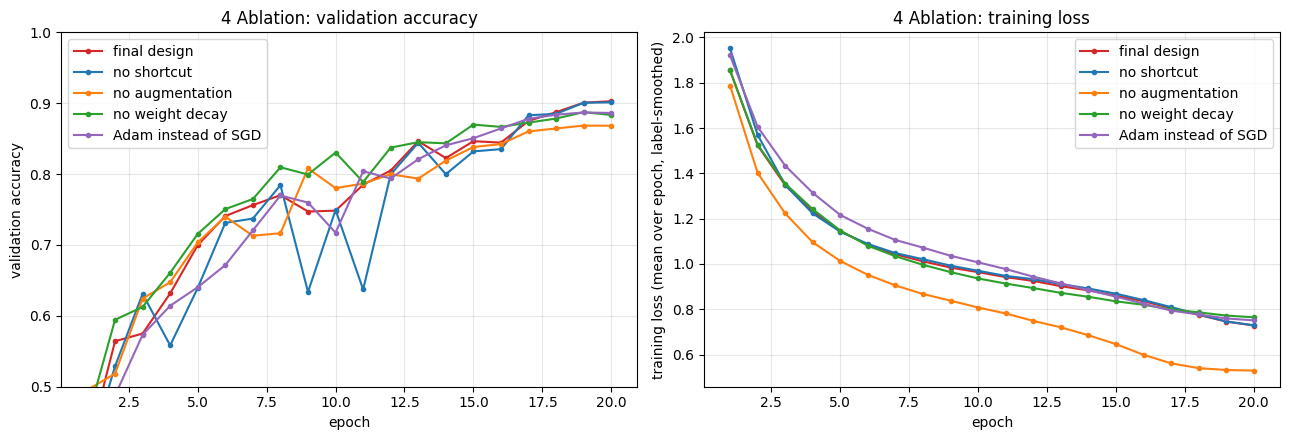

In [26]:
table_4 = pd.DataFrame([dict(run=name, final_val_acc=h['val_acc'][-1], best_val_acc=max(h['val_acc']),
                             final_train_loss=h['train_loss'][-1], minutes=h['time'] / 60)
                        for name, h in results_4.items()]).set_index('run')
table_4['val_acc_change'] = table_4['final_val_acc'] - table_4.loc['final design', 'final_val_acc']
display(table_4.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, h), color in zip(results_4.items(), ['C3', 'C0', 'C1', 'C2', 'C4']):
    ep = range(1, len(h['val_acc']) + 1)
    ax1.plot(ep, h['val_acc'], 'o-', ms=3, color=color, label=name)
    ax2.plot(ep, h['train_loss'], 'o-', ms=3, color=color, label=name)
ax1.set(xlabel='epoch', ylabel='validation accuracy', title='4 Ablation: validation accuracy', ylim=(0.5, 1))
ax2.set(xlabel='epoch', ylabel='training loss (mean over epoch, label-smoothed)', title='4 Ablation: training loss')
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### Test accuracy (evaluated once)

This is the only place in the notebook where the test set is used. I pick the run with the highest validation
accuracy from the ablation, load its saved weights, load the 10k test images for the first time, normalize them with
the mean and standard deviation of the 45k training images (not with the test images' own statistics), and evaluate
once. Nothing above was chosen by looking at test accuracy, so this number is an honest estimate of how the model does
on unseen data.

In [27]:
best_run = table_4['final_val_acc'].idxmax()
cfg = {**BASE_4, **ABLATIONS_4[best_run]}
final_model = CifarResNet(DEPTH_4, residual=cfg['residual'], widths=WIDTHS_4).to(device, memory_format=torch.channels_last)
final_model.load_state_dict(torch.load(f"{RESULTS_DIR}/4_{best_run.replace(' ', '_')}.pt", map_location=device))
print(f"selected on validation accuracy: '{best_run}', {count_params(final_model)} parameters, "
      f"val acc {table_4.loc[best_run, 'final_val_acc']:.4f}")

test_images, test_labels = load_cifar10('test')
X_test = normalize(torch.tensor(test_images).permute(0, 3, 1, 2).float().div(255)).to(device)
Y_test = torch.tensor(test_labels).to(device)
test_loss, test_acc = evaluate(final_model, X_test, Y_test)
print(f'TEST accuracy: {test_acc:.4f}   (test loss {test_loss:.4f}, {len(X_test)} images, evaluated once)')

selected on validation accuracy: 'final design', 386626 parameters, val acc 0.9028
CIFAR-10 test: downloaded and decoded in 2 s
TEST accuracy: 0.8961   (test loss 0.3631, 10000 images, evaluated once)


**Interpretation.**

**Test accuracy: 89.6%** for the final design (386,626 parameters, 20 epochs, about 1.5 minutes of training on the T4).
Its validation accuracy was 90.3%, so the test result is only 0.7 points lower. With 5k validation and 10k test images
a difference that small is about what noise alone would give, so choosing between five configurations on the
validation set didn't noticeably overfit to it.

**Ablation** (change in validation accuracy compared with the final design):
- **No augmentation: −3.5 points** (86.8%), the biggest effect. Without augmentation the training loss goes much lower
  (0.53 vs 0.73), but validation accuracy is worse, so the network is overfitting. Even with 45k images and only 20
  epochs, augmentation mattered the most.
- **No weight decay: −1.9 points** (88.3%). Without weight decay the network was actually ahead for much of training,
  but it gained less at the end when the learning rate dropped. Weight decay seems to pay off mainly in the final,
  low-learning-rate part of training.
- **Adam instead of SGD: −1.7 points** (88.6%). Adam started slower and never caught up. It was also about 35% slower
  per run (2.0 vs 1.5 minutes), because my Adam class loops over the parameters in Python while PyTorch's SGD updates
  all of them with multi-tensor kernels. For CNNs like this one, SGD with momentum and a good schedule usually ends up a
  little better than Adam, and that's what happened here.
- **No shortcut: −0.2 points** (90.1%), which is within noise. At depth 14 the plain network can still be optimized
  fine, which agrees with 3(b), where the shortcut only made a real difference at depth 56. The shortcut did make
  training more *stable*, though: the plain network's validation accuracy dropped sharply during the high-learning-rate
  phase (to about 56% at epoch 4 and 63% at epochs 9 and 11), while the residual network climbed much more smoothly.

So the choices that mattered most were augmentation, then weight decay and the optimizer, while the shortcut mainly
helped stability at this depth. Every run used one seed. The standard error of a validation accuracy around 90% is
about 0.4 points, so the 0.2-point shortcut difference means nothing, while the 1.7 to 3.5 point differences are well
above the noise.